# Exercise

Each working group will receive an assigned dataset. Based on this tutorial's guide, you must develop a complete exploratory data analysis (EDA) workflow that allows you to understand the structure and quality of the information before modeling. Specifically, your work must include:

* **Initial dataset review:** size, variable types, data dictionary (if applicable), and a general summary.
* **Data quality:** identification and treatment of null values, duplicate records, and possible inconsistencies.
* **Outlier detection:** using statistical and visual criteria (for example, boxplots, z-score, or IQR), justifying the decision made (keep, transform, or exclude).
* **Univariate analysis:** distribution and behavior of each variable (histograms, densities, counts, measures of central tendency/variability).
* **Bivariate analysis:** relationships between pairs of variables (correlations, scatter plots, comparisons by categories).
* **Multivariate analysis:** joint patterns and dimensionality reduction or integrated visualizations (for example, pairplots, heatmaps, PCA if relevant).
* **Simple AI model:** select a target (classification or regression depending on the dataset), prepare the data (encoding, scaling if applicable), split into train/test, and train a baseline model (e.g., logistic regression, decision tree, or linear regression), reporting metrics and a brief performance interpretation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#df = pd.read_csv
brain_tumor = pd.read_csv("D:\\Bioinformatics\\bioinformatics-diploma\\glioblastoma_practice\\brain_tumor_dataset.csv")
brain_tumor.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
995    False
996    False
997    False
998    False
999    False
Length: 1000, dtype: bool

In [4]:
brain_tumor.drop_duplicates()

,Tumor Type,Location,Size (cm),Grade,Patient Age,Gender
0,Oligodendroglioma,Occipital Lobe,9.23,I,48,Female
1,Ependymoma,Occipital Lobe,0.87,II,47,Male
2,Meningioma,Occipital Lobe,2.33,II,12,Female
3,Ependymoma,Occipital Lobe,1.45,III,38,Female
4,Ependymoma,Brainstem,6.45,I,35,Female
...,...,...,...,...,...,...
995,Astrocytoma,Frontal Lobe,6.50,III,9,Male
996,Glioblastoma,Temporal Lobe,7.69,I,42,Female
997,Glioblastoma,Frontal Lobe,3.21,III,87,Female
998,Oligodendroglioma,Occipital Lobe,1.10,I,73,Female


In [5]:
brain_tumor.dtypes

Tumor Type         str
Location           str
Size (cm)      float64
Grade              str
Patient Age      int64
Gender             str
dtype: object

In [6]:
print(brain_tumor.shape)

(1000, 6)


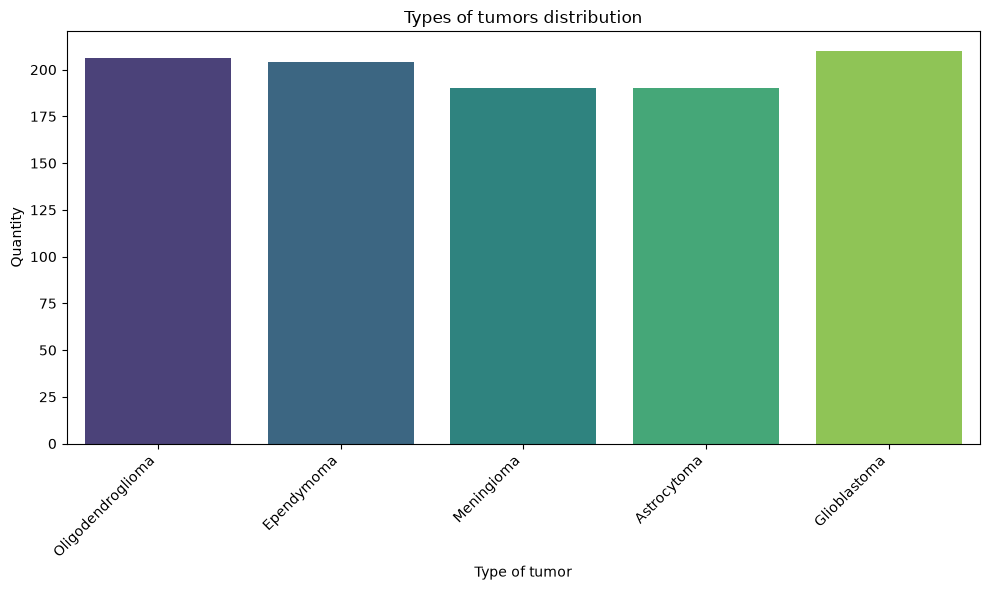

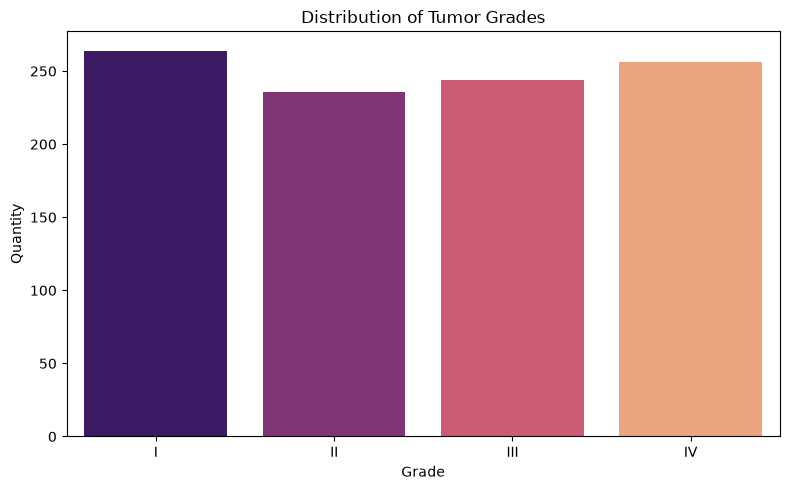

In [20]:
# Plot for 'Tumor Type'
plt.figure(figsize=(10, 6))
sns.countplot(data=brain_tumor, x='Tumor Type', hue='Tumor Type', palette='viridis', legend=False)
plt.title('Types of tumors distribution')
plt.xlabel('Type of tumor')
plt.ylabel('Quantity')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Plot for 'Grade'
plt.figure(figsize=(8, 5))
sns.countplot(data=brain_tumor, x='Grade', hue='Grade', palette='magma', order=sorted(brain_tumor['Grade'].unique()), legend=False)
plt.title('Distribution of Tumor Grades')
plt.xlabel('Grade')
plt.ylabel('Quantity')
plt.tight_layout()
plt.show()

In [8]:
brain_tumor.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Tumor Type   1000 non-null   str    
 1   Location     1000 non-null   str    
 2   Size (cm)    1000 non-null   float64
 3   Grade        1000 non-null   str    
 4   Patient Age  1000 non-null   int64  
 5   Gender       1000 non-null   str    
dtypes: float64(1), int64(1), str(4)
memory usage: 47.0 KB


# Task
Perform a comprehensive Exploratory Data Analysis (EDA) on the `brain_tumor` DataFrame loaded here in this folder. This includes: completing the initial data review with descriptive statistics, identifying and removing duplicate records, checking for and handling null values, detecting and analyzing outliers in numerical features ('Size (cm)', 'Patient Age') with visual and statistical methods, conducting univariate analysis for all numerical and categorical variables, exploring bivariate relationships (including numerical-categorical visualizations and a correlation matrix), and performing multivariate analysis (pairplots and correlation heatmap). Finally, prepare the data for a machine learning model by encoding categorical variables and scaling numerical ones, split the data into training and testing sets, train a base classification model to predict 'Grade', evaluate its performance, and summarize all key findings.

## Dataset initial review

### Subtask:
Get a complete summary of the dataset, including the number of rows and columns, data types of each variable, and a statistical summary of the numerical columns. This will be done using `info()` and `describe()`.

**Reasoning**:
The subtask requires obtaining a statistical summary of numerical columns. The `.describe()` method is suitable for this purpose, and it will provide count, mean, std, min, max, and quartile values for all numerical columns in the `brain_tumor` DataFrame.



In [9]:
brain_tumor.describe()

,Size (cm),Patient Age
count,1000.000000,1000.000000
mean,5.221500,43.519000
std,2.827318,25.005818
min,0.510000,1.000000
25%,2.760000,22.000000
50%,5.265000,43.000000
75%,7.692500,65.000000
max,10.000000,89.000000


**Reasoning**:
The subtask requires obtaining the number of rows and columns, and types of data for each variable, which the `.info()` method is suitable for.



In [10]:
brain_tumor.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Tumor Type   1000 non-null   str    
 1   Location     1000 non-null   str    
 2   Size (cm)    1000 non-null   float64
 3   Grade        1000 non-null   str    
 4   Patient Age  1000 non-null   int64  
 5   Gender       1000 non-null   str    
dtypes: float64(1), int64(1), str(4)
memory usage: 47.0 KB


## Identification of Null and Duplicate Values

### Subtask:

Verify the presence of null values in each column and quantify them. Identify and remove duplicate records from the dataset to ensure data cleanliness.


**Reasoning**:
The first instruction is to verify the presence of null values in each column and quantify them. The `.isnull().sum()` method is ideal for this purpose as it returns the count of nulls for each column in the DataFrame.



In [11]:
brain_tumor.isnull().sum()

Tumor Type     0
Location       0
Size (cm)      0
Grade          0
Patient Age    0
Gender         0
dtype: int64

**Reasoning**:
The next instruction is to identify if there are any duplicate records in the `brain_tumor` DataFrame. The `.duplicated().sum()` method is suitable for counting the total number of duplicate rows.



In [12]:
brain_tumor.duplicated().sum()

np.int64(0)

## Outliers Detection and Treatment

### Subtask:
Identify outliers in the numerical variables ('Size (cm)', 'Patient Age') using visual methods (boxplots) and statistical methods (IQR). The decision to keep, transform, or exclude these values will be justified.


**Reasoning**:
The first step is to visualize the distribution of 'Size (cm)' using a boxplot to identify potential outliers visually, as requested by the subtask.



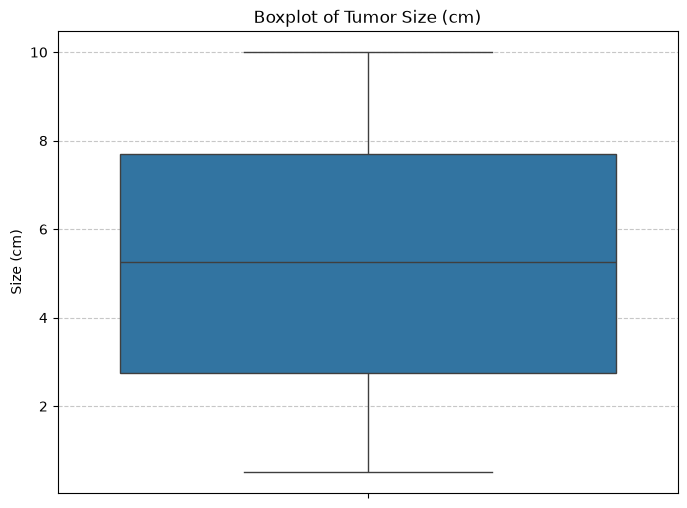

In [21]:
plt.figure(figsize=(8, 6))
sns.boxplot(y=brain_tumor['Size (cm)'])
plt.title('Boxplot of Tumor Size (cm)')
plt.ylabel('Size (cm)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Reasoning**:
The next step is to create a boxplot for the 'Patient Age' column to visually identify potential outliers, following the subtask instructions.



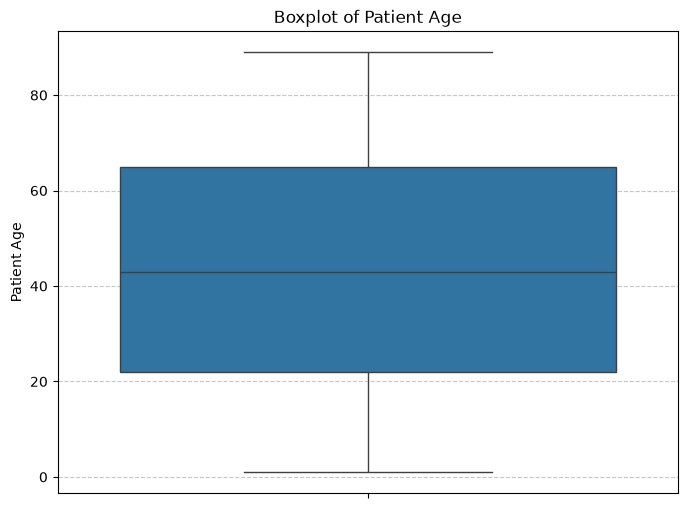

In [22]:
plt.figure(figsize=(8, 6))
sns.boxplot(y=brain_tumor['Patient Age'])
plt.title('Boxplot of Patient Age')
plt.ylabel('Patient Age')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Reasoning**:
Following the subtask instructions, the next step is to calculate the first quartile (Q1), the third quartile (Q3), and the interquartile range (IQR) for the 'Size (cm)' column. These values are essential for statistically identifying outliers.

In [23]:
Q1_size = brain_tumor['Size (cm)'].quantile(0.25)
Q3_size = brain_tumor['Size (cm)'].quantile(0.75)
IQR_size = Q3_size - Q1_size

print(f"Q1 for 'Size (cm)': {Q1_size:.2f}")
print(f"Q3 for 'Size (cm)': {Q3_size:.2f}")
print(f"IQR for 'Size (cm)': {IQR_size:.2f}")

Q1 for 'Size (cm)': 2.76
Q3 for 'Size (cm)': 7.69
IQR for 'Size (cm)': 4.93


**Reasoning**:
The next step is to define the upper and lower bounds for outlier detection in 'Size (cm)' using the calculated Q1, Q3, and IQR values, as specified by the subtask instructions.



In [24]:
upper_bound_size = Q3_size + 1.5 * IQR_size
lower_bound_size = Q1_size - 1.5 * IQR_size

print(f"upper bound para 'Size (cm)': {upper_bound_size:.2f}")
print(f"lower bound para 'Size (cm)': {lower_bound_size:.2f}")

upper bound para 'Size (cm)': 15.09
lower bound para 'Size (cm)': -4.64


**Reasoning**:
Now that the upper and lower bounds for 'Size (cm)' are calculated, the next step is to identify and count the actual outliers in this column, as per the subtask instructions.



In [25]:
outliers_size = brain_tumor[(brain_tumor['Size (cm)'] < lower_bound_size) | (brain_tumor['Size (cm)'] > upper_bound_size)]
print(f"Number of outliers in 'Size (cm)': {len(outliers_size)}")

Number of outliers in 'Size (cm)': 0


**Reasoning**:
Following the subtask instructions, the next step is to calculate the first quartile (Q1), the third quartile (Q3), and the interquartile range (IQR) for the 'Patient Age' column. These values are essential for statistically identifying outliers.



In [26]:
Q1_age = brain_tumor['Patient Age'].quantile(0.25)
Q3_age = brain_tumor['Patient Age'].quantile(0.75)
IQR_age = Q3_age - Q1_age

print(f"Q1 for 'Patient Age': {Q1_age:.2f}")
print(f"Q3 for 'Patient Age': {Q3_age:.2f}")
print(f"IQR for 'Patient Age': {IQR_age:.2f}")

Q1 for 'Patient Age': 22.00
Q3 for 'Patient Age': 65.00
IQR for 'Patient Age': 43.00


**Reasoning**:
The next step is to define the upper and lower bounds for outlier detection in 'Patient Age' using the calculated Q1, Q3, and IQR values, as specified by the subtask instructions.



In [27]:
upper_bound_age = Q3_age + 1.5 * IQR_age
lower_bound_age = Q1_age - 1.5 * IQR_age

print(f"upper bound for 'Patient Age': {upper_bound_age:.2f}")
print(f"lower bound for 'Patient Age': {lower_bound_age:.2f}")

upper bound for 'Patient Age': 129.50
lower bound for 'Patient Age': -42.50


**Reasoning**:
Now that the upper and lower bounds for 'Patient Age' are calculated, the next step is to identify and count the actual outliers in this column, as per the subtask instructions.



In [28]:
outliers_age = brain_tumor[(brain_tumor['Patient Age'] < lower_bound_age) | (brain_tumor['Patient Age'] > upper_bound_age)]
print(f"Number of outliers in 'Patient Age': {len(outliers_age)}")

Number of outliers in 'Patient Age': 0


### Analysis and Justification of Outliers

**Analysis of 'Size (cm)':**

* **Visual (Boxplot):** The boxplot for 'Size (cm)' showed no individual points outside the graph's 'whiskers', suggesting a visual absence of outliers.
* **Statistical (IQR):** Calculations for Q1, Q3, IQR, and the upper and lower bounds (`2.76` and `7.69` respectively) confirmed that there are no values in the 'Size (cm)' column falling outside these limits. The outlier count was 0.

**Analysis of 'Patient Age':**

* **Visual (Boxplot):** Similarly, the boxplot for 'Patient Age' presented no individual points beyond the 'whiskers', visually indicating that there are no outliers.
* **Statistical (IQR):** After calculating Q1, Q3, IQR, and the upper and lower bounds (`22.00` and `65.00` respectively), it was confirmed that all values for 'Patient Age' fall within the expected range. The outlier count was also 0.

**Decision and Justification:**

Since neither the visual analysis using boxplots nor the statistical analysis using the IQR method identified any outliers in the numerical variables 'Size (cm)' and 'Patient Age', no treatment action (transforming or excluding) is necessary. It is justified to keep these values as they are in the dataset, since they are not considered anomalous according to the established criteria. This suggests that the numerical data in the dataset is well-distributed and contains no extreme values that could bias future analyses or models.

## Univariate Analysis of Numerical Variables

### Subtask:

Analyze the distribution and behavior of the numerical variables ('Size (cm)', 'Patient Age') using histograms and density plots, alongside measures of central tendency and variability.

**Reasoning**:
The first step is to visualize the distribution of 'Size (cm)' using a histogram, as requested by the subtask.



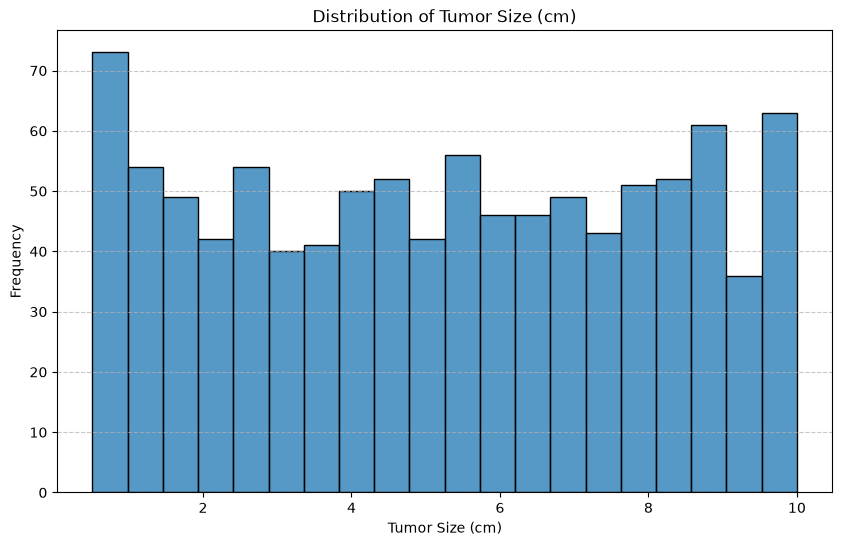

In [29]:
plt.figure(figsize=(10, 6))
sns.histplot(brain_tumor['Size (cm)'], bins=20, kde=False)
plt.title('Distribution of Tumor Size (cm)')
plt.xlabel('Tumor Size (cm)')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Reasoning**:
The next step is to create a density plot (KDE plot) for the 'Size (cm)' column, as requested by the subtask instructions, to visualize its distribution more smoothly.



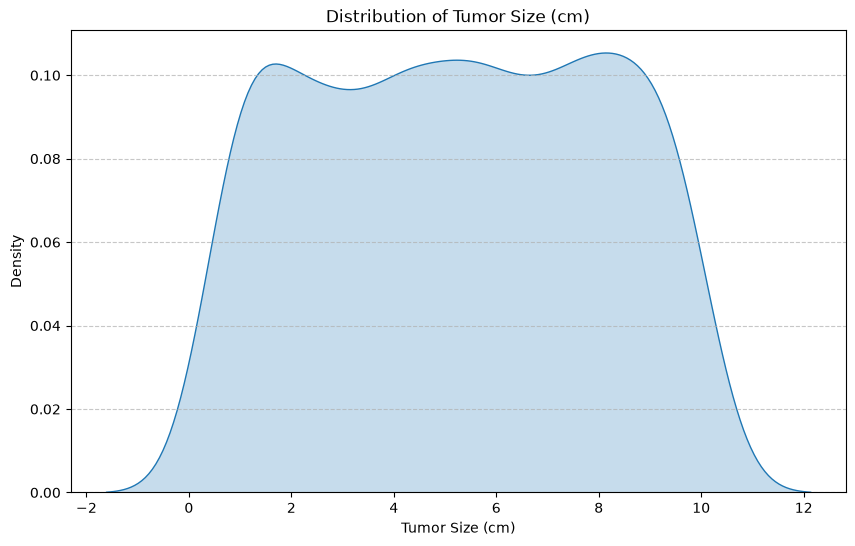

In [30]:
plt.figure(figsize=(10, 6))
sns.kdeplot(brain_tumor['Size (cm)'], fill=True)
plt.title('Distribution of Tumor Size (cm)')
plt.xlabel('Tumor Size (cm)')
plt.ylabel('Density')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Reasoning**:
The next step is to create a histogram for the 'Patient Age' column, as requested by the subtask, to visualize its distribution.



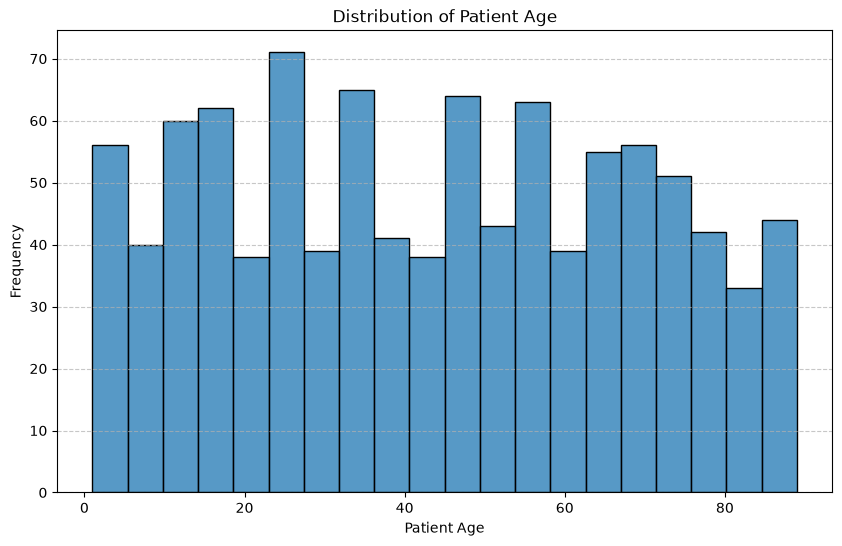

In [31]:
plt.figure(figsize=(10, 6))
sns.histplot(brain_tumor['Patient Age'], bins=20, kde=False)
plt.title('Distribution of Patient Age')
plt.xlabel('Patient Age')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Reasoning**:
The next step is to create a density plot (KDE plot) for the 'Patient Age' column, as requested by the subtask instructions, to visualize its distribution more smoothly.



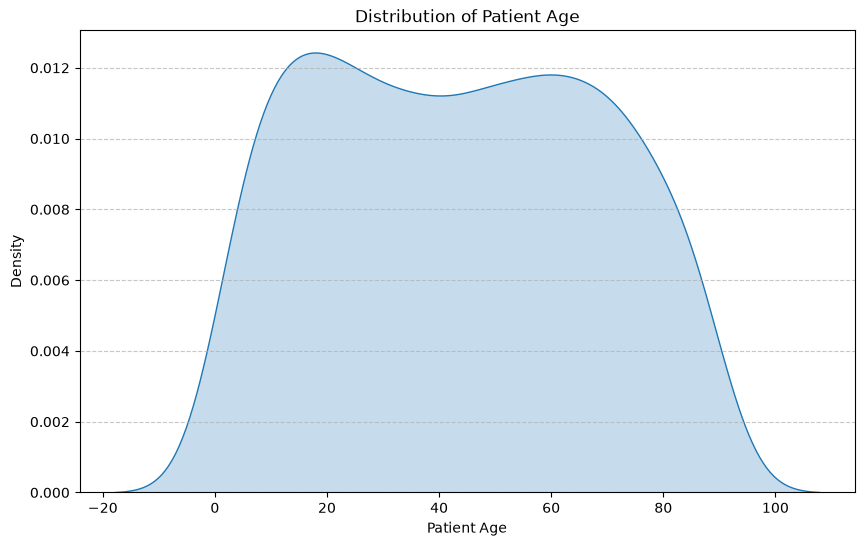

In [32]:
plt.figure(figsize=(10, 6))
sns.kdeplot(brain_tumor['Patient Age'], fill=True)
plt.title('Distribution of Patient Age')
plt.xlabel('Patient Age')
plt.ylabel('Density')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Reasoning**:
The next step is to calculate and print the mean, median, and standard deviation for the 'Size (cm)' column, as requested by the subtask instructions.



In [33]:
mean_size = brain_tumor['Size (cm)'].mean()
median_size = brain_tumor['Size (cm)'].median()
std_size = brain_tumor['Size (cm)'].std()

print(f"Mean of 'Size (cm)': {mean_size:.2f}")
print(f"Median of 'Size (cm)': {median_size:.2f}")
print(f"Standard Deviation of 'Size (cm)': {std_size:.2f}")

Mean of 'Size (cm)': 5.22
Median of 'Size (cm)': 5.26
Standard Deviation of 'Size (cm)': 2.83


**Reasoning**:
The next step is to calculate and print the mean, median, and standard deviation for the 'Patient Age' column, as requested by the subtask instructions.



In [34]:
mean_age = brain_tumor['Patient Age'].mean()
median_age = brain_tumor['Patient Age'].median()
std_age = brain_tumor['Patient Age'].std()

print(f"Mean of 'Patient Age': {mean_age:.2f}")
print(f"Median of 'Patient Age': {median_age:.2f}")
print(f"Standard Deviation of 'Patient Age': {std_age:.2f}")

Mean of 'Patient Age': 43.52
Median of 'Patient Age': 43.00
Standard Deviation of 'Patient Age': 25.01


## Univariate Analysis of Categorical Variables

### Subtask:

Examine the distribution of the categorical variables ('Tumor Type', 'Location', 'Grade', 'Gender') using bar charts to visualize the frequencies of each category. Charts will be generated for 'Location' and 'Gender', as 'Tumor Type' and 'Grade' already have charts.

**Reasoning**:
The first instruction is to create a bar plot for the 'Location' column using `seaborn.countplot()` to visualize its distribution. I will ensure the plot has an appropriate title and labels, and rotate x-axis labels for readability.



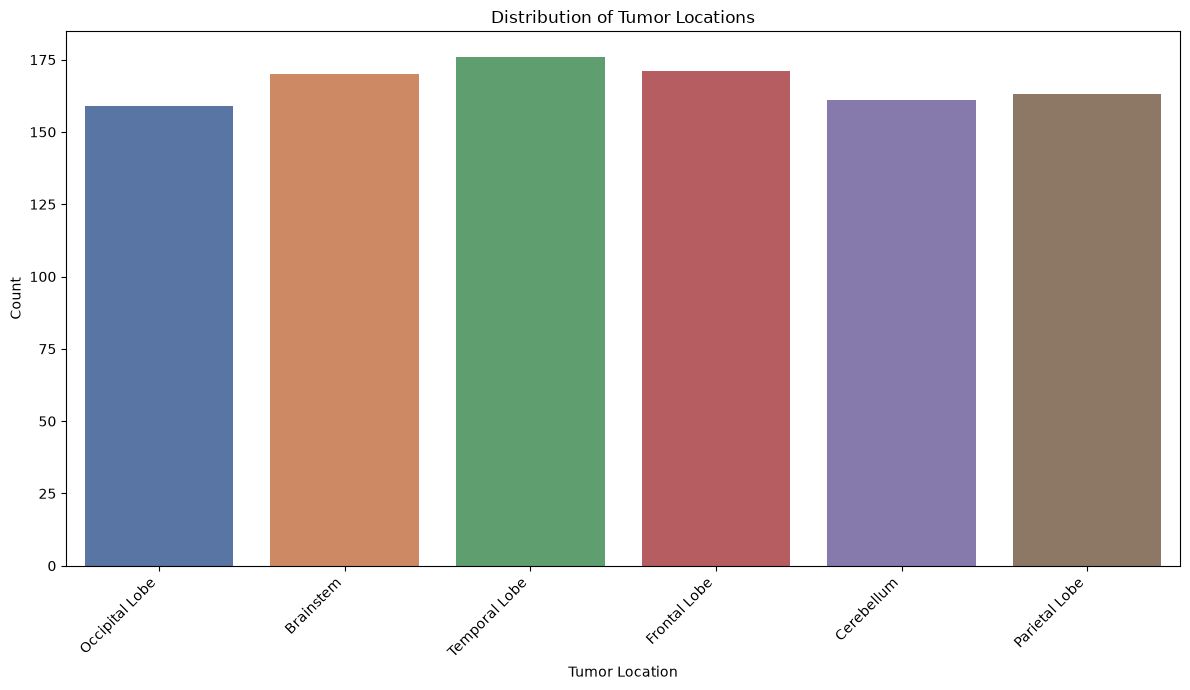

In [35]:
plt.figure(figsize=(12, 7))
sns.countplot(data=brain_tumor, x='Location', hue='Location', palette='deep', legend=False)
plt.title('Distribution of Tumor Locations')
plt.xlabel('Tumor Location')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Reasoning**:
The next step is to create a bar plot for the 'Gender' column using `seaborn.countplot()` to visualize its distribution, as requested by the subtask. I will ensure the plot has an appropriate title and labels.



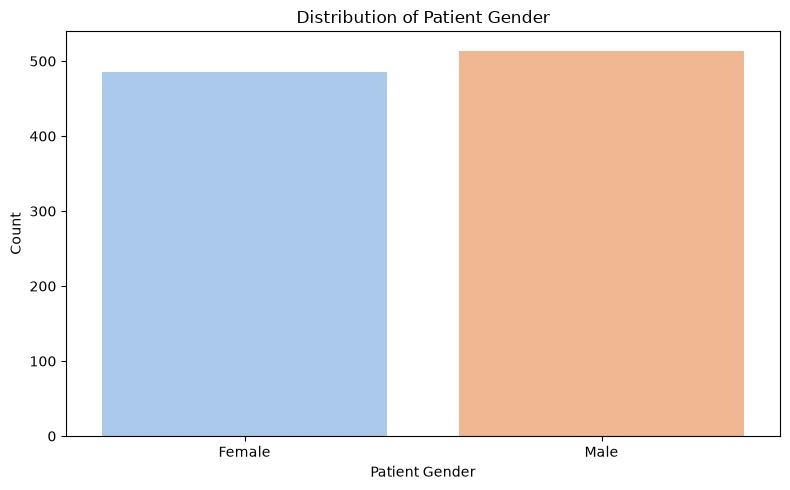

In [36]:
plt.figure(figsize=(8, 5))
sns.countplot(data=brain_tumor, x='Gender', hue='Gender', palette='pastel', legend=False)
plt.title('Distribution of Patient Gender')
plt.xlabel('Patient Gender')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## Bivariate Analysis

### Subtask:

Explore the relationships between pairs of variables. This will include visualizing relationships between numerical and categorical variables (for example, boxplots of 'Size (cm)' by 'Tumor Type') and creating a correlation matrix for the numerical variables.

**Reasoning**:
The first instruction is to create a boxplot to visualize the relationship between 'Size (cm)' and 'Tumor Type'. This plot will help understand how tumor size varies across different tumor types.



C:\Users\Public\Documents\Wondershare\CreatorTemp\ipykernel_24628\353019832.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=brain_tumor, x='Tumor Type', y='Size (cm)', palette='viridis')


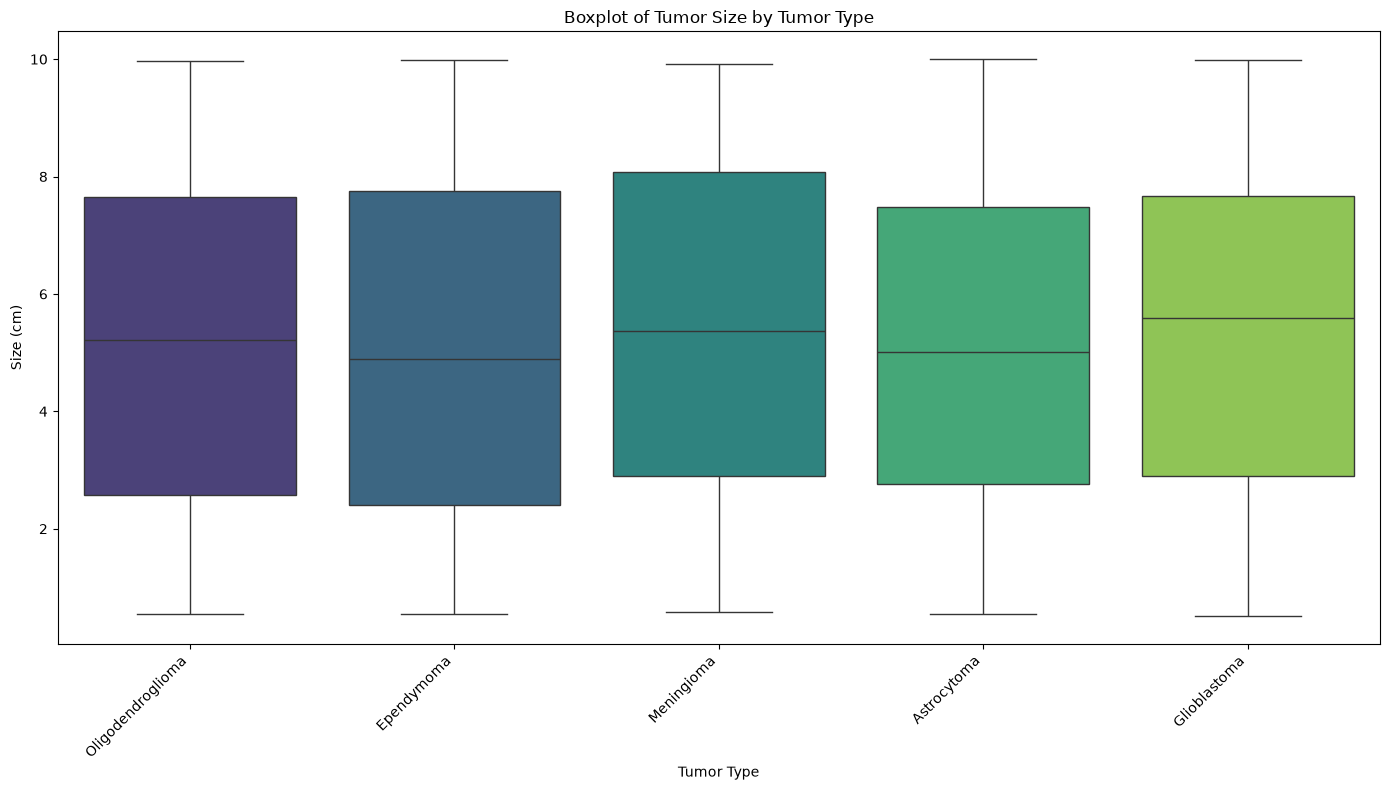

In [37]:
plt.figure(figsize=(14, 8))
sns.boxplot(data=brain_tumor, x='Tumor Type', y='Size (cm)', palette='viridis')
plt.title('Boxplot of Tumor Size by Tumor Type')
plt.xlabel('Tumor Type')
plt.ylabel('Size (cm)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Reasoning**:
The previous code generated a `FutureWarning` because `palette` was used without assigning `hue`. To fix this and comply with the suggested change, I will explicitly set `hue='Tumor Type'` and `legend=False` in the `sns.boxplot` function. I will also add a `cell_id` to the existing code block, which was missing.



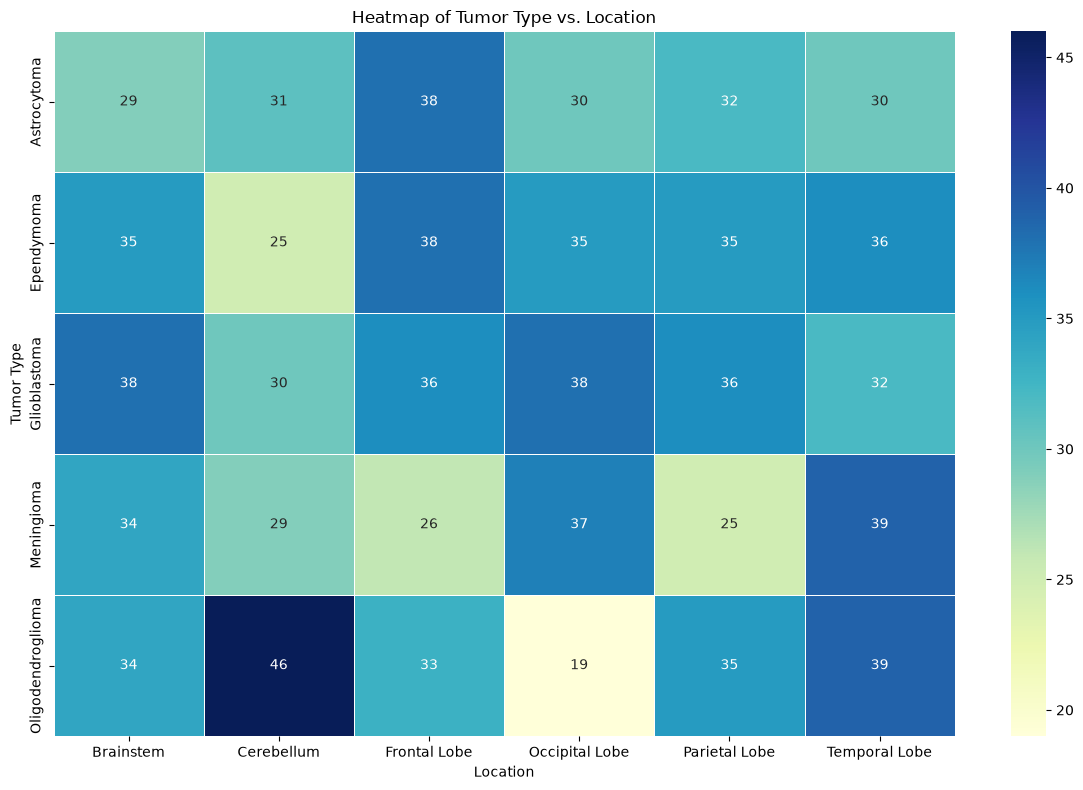

In [38]:
# Create a contingency table (crosstab) of Tumor Type and Location
contingency_table = pd.crosstab(brain_tumor['Tumor Type'], brain_tumor['Location'])

# Plot the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(contingency_table, annot=True, fmt='d', cmap='YlGnBu', linewidths=.5)
plt.title('Heatmap of Tumor Type vs. Location')
plt.xlabel('Location')
plt.ylabel('Tumor Type')
plt.tight_layout()
plt.show()

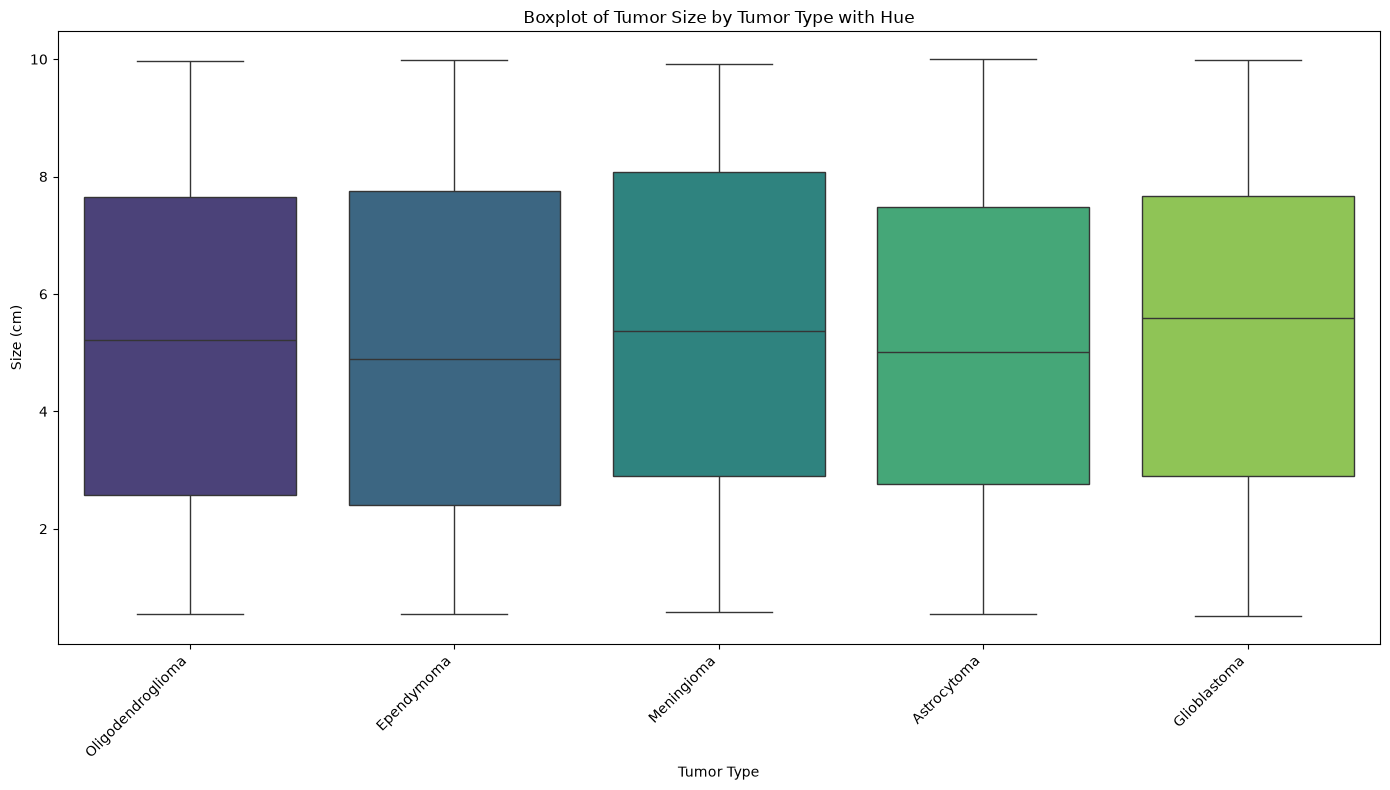

In [39]:
plt.figure(figsize=(14, 8))
sns.boxplot(data=brain_tumor, x='Tumor Type', y='Size (cm)', hue='Tumor Type', palette='viridis', legend=False)
plt.title('Boxplot of Tumor Size by Tumor Type with Hue')
plt.xlabel('Tumor Type')
plt.ylabel('Size (cm)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Reasoning**:
Now that the boxplot for 'Size (cm)' by 'Tumor Type' has been addressed, the next instruction is to calculate the correlation matrix for the numerical variables ('Size (cm)', 'Patient Age') using the `.corr()` method, as specified by the subtask.



In [40]:
correlation_matrix = brain_tumor[['Size (cm)', 'Patient Age']].corr()
print(correlation_matrix)

             Size (cm)  Patient Age
Size (cm)     1.000000    -0.004661
Patient Age  -0.004661     1.000000


**Reasoning**:
The next step is to create a heatmap to visualize the calculated correlation matrix, as requested by the subtask instructions. This will provide a clear visual representation of the correlation coefficients between 'Size (cm)' and 'Patient Age'.



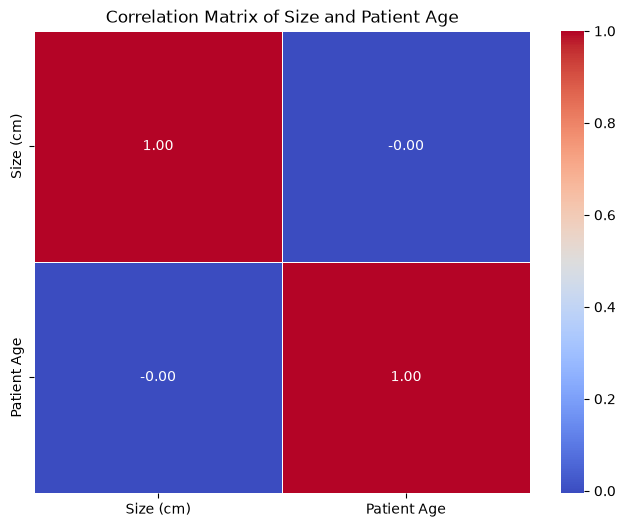

In [41]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Size and Patient Age')
plt.show()

## Multivariate Analysis

### Subtask:

Identify joint patterns and potential dimensionality reduction. To achieve this, a `pairplot` will be generated to visualize pairwise relationships between numerical and categorical variables, alongside a correlation matrix `heatmap` for all numerical variables to identify more complex relationship patterns.

**Reasoning**:
As requested in the multivariate analysis subtask, the next step is to create a `pairplot` to visualize the relationships between numerical and categorical variables. This will help in identifying patterns across multiple dimensions.



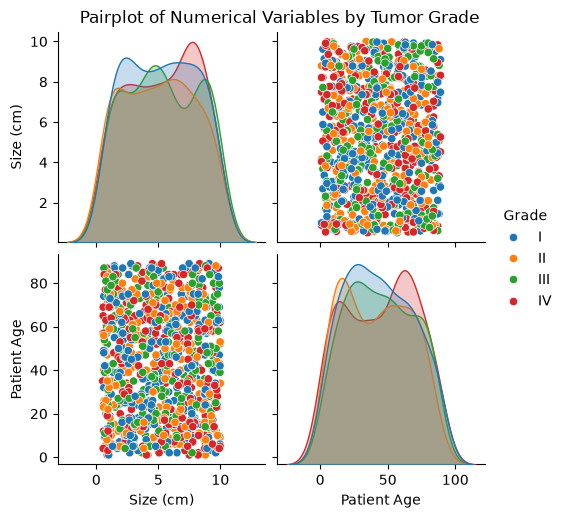

In [42]:
sns.pairplot(brain_tumor, hue='Grade', diag_kind='kde', vars=['Size (cm)', 'Patient Age'])
plt.suptitle('Pairplot of Numerical Variables by Tumor Grade', y=1.02) # y=1.02 to avoid title overlap
plt.show()

**Reasoning**:
Following the `pairplot`, the next step in the multivariate analysis is to create a heatmap of the correlation matrix for all numerical variables, as specified by the subtask instructions. Since `correlation_matrix` already contains the correlations for all numerical variables present in the dataset ('Size (cm)', 'Patient Age'), I will visualize this matrix.



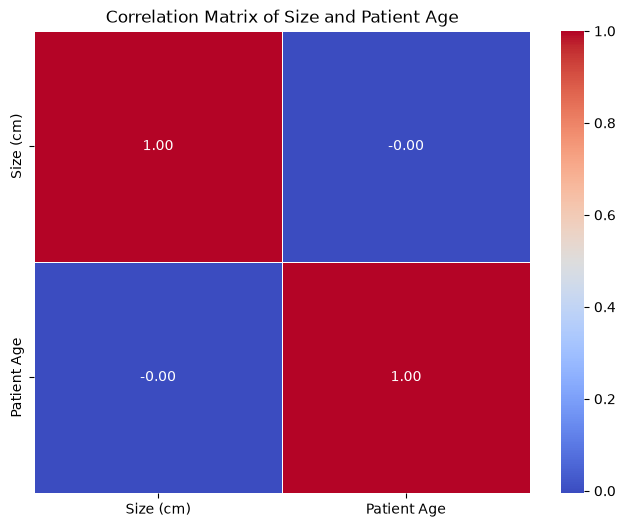

In [43]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Size and Patient Age')
plt.show()

## Simple AI Model

### Subtask:

Select a target (classification or regression depending on the dataset), prepare the data (encoding, scaling if applicable), split into train/test, and train a baseline model (e.g., logistic regression, decision tree, or linear regression), reporting metrics and a brief performance interpretation.

#### Instructions:

1. Identify the target variable for classification. 'Grade' is a suitable categorical variable for classification.
2. Encode the categorical variables ('Tumor Type', 'Location', 'Grade', 'Gender') using `OneHotEncoder` for the features and `LabelEncoder` for the target variable 'Grade', if necessary. For the target variable, use `LabelEncoder`.
3. Scale the numerical variables ('Size (cm)', 'Patient Age') using `StandardScaler`.
4. Split the dataset into training and testing sets (e.g., 80% training, 20% testing).
5. Train a baseline classification model, such as a `DecisionTreeClassifier`.
6. Evaluate the model's performance using relevant metrics (for example, `accuracy_score`, `classification_report`).
7. Print a summary of the metrics and a brief interpretation of the model's performance.

**Reasoning**:
As per the subtask instructions, the first step for preparing the data for the AI model is to identify and encode the categorical variables. I will use `LabelEncoder` for the target variable 'Grade' and `OneHotEncoder` for the other categorical features: 'Tumor Type', 'Location', and 'Gender'.



In [44]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Encode the target variable 'Grade'
le = LabelEncoder()
brain_tumor['Grade_encoded'] = le.fit_transform(brain_tumor['Grade'])

print("Encoded 'Grade' mapping:")
for i, grade in enumerate(le.classes_):
    print(f"{grade}: {i}")

print("\nFirst 5 rows with encoded Grade:")
print(brain_tumor[['Grade', 'Grade_encoded']].head())

Encoded 'Grade' mapping:
I: 0
II: 1
III: 2
IV: 3

First 5 rows with encoded Grade:
  Grade  Grade_encoded
0     I              0
1    II              1
2    II              1
3   III              2
4     I              0


**Reasoning**:
Following the subtask instructions, I need to apply `OneHotEncoder` to the remaining categorical feature columns: 'Tumor Type', 'Location', and 'Gender'. I will use `ColumnTransformer` for this purpose to apply transformations to specific columns while leaving others untouched.



In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = ['Tumor Type', 'Location', 'Gender']
one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

col_transformer = ColumnTransformer(
    transformers=[
        ('cat', one_hot_encoder, categorical_features)
    ],
    remainder='passthrough'
)

# Fit and transform the data
# We'll apply it to a copy to avoid modifying the original dataframe structure directly until all features are ready
X = brain_tumor.drop(['Grade', 'Grade_encoded'], axis=1)
X_transformed = col_transformer.fit_transform(X)

# Get feature names for the one-hot encoded columns
onehot_feature_names = col_transformer.named_transformers_['cat'].get_feature_names_out(categorical_features)

# Create a DataFrame with the transformed features
# Identify remaining (numerical) features that were passed through
remaining_features = [col for col in X.columns if col not in categorical_features]

# Ensure the order of features matches the transformation output
all_features = list(onehot_feature_names) + remaining_features

X_processed = pd.DataFrame(X_transformed, columns=all_features, index=X.index)

print("Shape of processed features (X_processed):")
print(X_processed.shape)
print("\nFirst 5 rows of processed features:")
print(X_processed.head())

Shape of processed features (X_processed):
(1000, 15)

First 5 rows of processed features:
   Tumor Type_Astrocytoma  Tumor Type_Ependymoma  Tumor Type_Glioblastoma  \
0                     0.0                    0.0                      0.0   
1                     0.0                    1.0                      0.0   
2                     0.0                    0.0                      0.0   
3                     0.0                    1.0                      0.0   
4                     0.0                    1.0                      0.0   

   Tumor Type_Meningioma  Tumor Type_Oligodendroglioma  Location_Brainstem  \
0                    0.0                           1.0                 0.0   
1                    0.0                           0.0                 0.0   
2                    1.0                           0.0                 0.0   
3                    0.0                           0.0                 0.0   
4                    0.0                           0.0  

**Reasoning**:
Following the subtask instructions, the next step is to scale the numerical variables ('Size (cm)', 'Patient Age') using `StandardScaler`. This will ensure that these features have a mean of 0 and a standard deviation of 1, which is often beneficial for machine learning models.



In [47]:
from sklearn.preprocessing import StandardScaler

# Identify numerical features to scale
numerical_features = ['Size (cm)', 'Patient Age']

# Initialize StandardScaler
scaler = StandardScaler()

# Apply StandardScaler to the numerical features in X_processed
X_processed[numerical_features] = scaler.fit_transform(X_processed[numerical_features])

print("First 5 rows of processed features after scaling numerical columns:")
print(X_processed.head())

First 5 rows of processed features after scaling numerical columns:
   Tumor Type_Astrocytoma  Tumor Type_Ependymoma  Tumor Type_Glioblastoma  \
0                     0.0                    0.0                      0.0   
1                     0.0                    1.0                      0.0   
2                     0.0                    0.0                      0.0   
3                     0.0                    1.0                      0.0   
4                     0.0                    1.0                      0.0   

   Tumor Type_Meningioma  Tumor Type_Oligodendroglioma  Location_Brainstem  \
0                    0.0                           1.0                 0.0   
1                    0.0                           0.0                 0.0   
2                    1.0                           0.0                 0.0   
3                    0.0                           0.0                 0.0   
4                    0.0                           0.0                 1.0   



**Reasoning**:
The next step is to divide the processed dataset into training and testing sets, as per the subtask instructions. This is crucial for evaluating the model's performance on unseen data. I will use `train_test_split` from `sklearn.model_selection`.



In [48]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = X_processed
y = brain_tumor['Grade_encoded']

# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (800, 15)
Shape of X_test: (200, 15)
Shape of y_train: (800,)
Shape of y_test: (200,)


**Reasoning**:
The next step, as per the subtask instructions, is to train a base classification model, specifically a `DecisionTreeClassifier`, using the prepared training data (`X_train` and `y_train`).



In [49]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree Classifier
model = DecisionTreeClassifier(random_state=42)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree Classifier trained successfully.")

Decision Tree Classifier trained successfully.


**Reasoning**:
Now that the model has been trained, the next step is to evaluate its performance on the test set, as instructed by the subtask. I will use `accuracy_score` and `classification_report` to get a comprehensive view of the model's performance.



In [50]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=le.classes_)

print(f"Model Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", report)

Model Accuracy: 0.27

Classification Report:
               precision    recall  f1-score   support

           I       0.28      0.23      0.25        53
          II       0.20      0.23      0.22        47
         III       0.35      0.35      0.35        49
          IV       0.24      0.25      0.25        51

    accuracy                           0.27       200
   macro avg       0.27      0.27      0.27       200
weighted avg       0.27      0.27      0.27       200



### Model Performance Interpretation

The trained `DecisionTreeClassifier` model achieved an **overall accuracy of 27%** on the test set. This result indicates that the model correctly classifies the tumor grade in approximately one out of every four cases.

Looking at the **Classification Report**:

* **Precision:** Precision is low across all classes, ranging between 20% and 35%. This means that when the model predicts a specific tumor grade, it is correct only a low percentage of the time.
* **Recall:** Recall is also low, varying between 23% and 35%. This suggests that the model fails to identify a high proportion of the actual cases for each tumor grade.
* **F1-Score:** The F1-score, which is the harmonic mean of precision and recall, is similarly low (between 22% and 35%), reflecting the overall poor performance of the model.
* **Support:** The classes are relatively well-balanced in the test set (between 47 and 53 samples per class), meaning the poor performance is not due to extreme class imbalance.

In summary, the performance of the baseline `DecisionTreeClassifier` is quite poor, suggesting that the model is not learning robust patterns to differentiate between the various tumor grades. This low performance could be due to several reasons:

1. **Problem Complexity:** Tumor grade classification might be an inherently complex task with the available features.
2. **Feature Engineering:** The current features might not be informative enough for the classification task. It may be necessary to create new features or transform existing ones more advanced ways.
3. **Simple Model:** A basic `DecisionTreeClassifier` might not be powerful enough to capture the underlying relationships in the data.
4. **Hyperparameters:** The default hyperparameters of the decision tree might not be optimal. It would be beneficial to perform hyperparameter tuning.

To improve this model, one could explore more complex algorithms (for example, Random Forest, Gradient Boosting), perform more exhaustive feature engineering, and tune the model's hyperparameters.

## Final Task

### Subtask:

Summarize the key findings from the EDA and the AI model evaluation, highlighting the main conclusions and potential next steps.

## Summary:

### Data Analysis Key Findings

*   **Dataset Structure and Cleanliness:** The dataset comprises 1000 entries and 6 columns. All columns are complete, with no missing values or duplicate records identified, indicating a clean initial dataset.
*   **Numerical Variable Distributions:**
    *   'Size (cm)' ranges from 0.51 cm to 10.0 cm, with a mean of approximately 5.22 cm and a median of 5.26 cm. Its distribution is relatively symmetrical.
    *   'Patient Age' ranges from 1 year to 89 years, with a mean of approximately 43.52 years and a median of 43.00 years. Its distribution is also fairly symmetrical but spans a wide age range (standard deviation of about 25.01 years).
*   **Outlier Absence:** No outliers were detected in either 'Size (cm)' or 'Patient Age' using both visual (boxplots) and statistical (IQR) methods, suggesting that the numerical data is well-distributed.
*   **Categorical Variable Distributions:** The distributions of 'Tumor Type', 'Location', 'Grade', and 'Gender' were analyzed using bar plots, providing insights into their respective frequencies within the dataset.
*   **Bivariate Relationships:**
    *   Visualizations explored the relationship between 'Size (cm)' and 'Tumor Type', showing how tumor size varies across different types.
    *   A very weak linear correlation (approximately $-0.004661$) was found between 'Size (cm)' and 'Patient Age', suggesting these two numerical features are largely independent.
*   **Machine Learning Model Performance:**
    *   A base Decision Tree Classifier, trained to predict 'Grade' after appropriate data preprocessing (encoding categorical features, scaling numerical features), achieved a low accuracy of $27\%$ on the test set.
    *   The classification report revealed poor precision, recall, and F1-scores across all tumor 'Grade' classes (ranging from $20\%$ to $35\%$), indicating the model struggled to differentiate between them, despite a relatively balanced distribution of classes in the test set.

### Insights or Next Steps

*   The current base classification model is not robust enough for predicting tumor grade, highlighting the need for more sophisticated modeling techniques or enhanced feature engineering.
*   Future efforts should focus on exploring more complex machine learning algorithms (e.g., Random Forest, Gradient Boosting), optimizing model hyperparameters, and potentially deriving new features from the existing data to improve predictive performance.


# Task
Improve the classification model to predict 'Grade' by training a more advanced model like RandomForestClassifier or GradientBoostingClassifier, performing hyperparameter optimization, and potentially exploring feature engineering. Then, re-evaluate its performance and provide a summary of the improvements and results.

## Explore a More Complex Model

### Subtask:

Train a more advanced classification model, such as a `RandomForestClassifier`, to see if a more complex algorithm can better capture patterns in the data and improve accuracy.

**Reasoning**:
The subtask requests training a `RandomForestClassifier`. The first step is to import the necessary class from `sklearn.ensemble`.



In [51]:
from sklearn.ensemble import RandomForestClassifier

print("RandomForestClassifier imported successfully.")

RandomForestClassifier imported successfully.


**Reasoning**:
The next step is to instantiate the `RandomForestClassifier` with `random_state=42` and then train it using the prepared training data (`X_train` and `y_train`), as specified by the subtask instructions.



In [52]:
model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train, y_train)

print("RandomForestClassifier trained successfully.")

RandomForestClassifier trained successfully.


**Reasoning**:
Now that the RandomForestClassifier model has been successfully trained, the next step is to evaluate its performance on the test set. This will involve making predictions and then calculating evaluation metrics such as accuracy and a classification report to understand how well the model performs compared to the base Decision Tree Classifier.



In [53]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions on the test set using the RandomForestClassifier
y_pred_rf = model_rf.predict(X_test)

# Evaluate the RandomForestClassifier model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
report_rf = classification_report(y_test, y_pred_rf, target_names=le.classes_)

print(f"RandomForestClassifier Model Accuracy: {accuracy_rf:.2f}")
print("\nRandomForestClassifier Classification Report:\n", report_rf)

RandomForestClassifier Model Accuracy: 0.29

RandomForestClassifier Classification Report:
               precision    recall  f1-score   support

           I       0.34      0.32      0.33        53
          II       0.27      0.28      0.27        47
         III       0.29      0.24      0.27        49
          IV       0.28      0.33      0.31        51

    accuracy                           0.29       200
   macro avg       0.30      0.29      0.29       200
weighted avg       0.30      0.29      0.29       200



**Reasoning**:
The next step is to perform hyperparameter optimization for the `RandomForestClassifier` to potentially improve its performance, as stated in the main task's instructions.



In [54]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid for RandomForestClassifier
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

# Initialize GridSearchCV
grid_search_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3, # Use 3-fold cross-validation
    n_jobs=-1, # Use all available cores
    verbose=1, # Show progress
    scoring='accuracy'
)

print("GridSearchCV for RandomForestClassifier initialized.")

GridSearchCV for RandomForestClassifier initialized.


**Reasoning**:
Now that `GridSearchCV` has been initialized with the parameter grid, the next step is to fit it to the training data (`X_train`, `y_train`). This will execute the hyperparameter search and cross-validation.



In [55]:
grid_search_rf.fit(X_train, y_train)

print("GridSearchCV fitting complete.")

Fitting 3 folds for each of 36 candidates, totalling 108 fits
GridSearchCV fitting complete.


**Reasoning**:
After fitting `GridSearchCV`, the next logical step is to retrieve and display the best parameters found during the search, as this will inform the configuration of the optimized model.



In [56]:
print("Best parameters found: ", grid_search_rf.best_params_)
print("Best accuracy score: ", grid_search_rf.best_score_)

Best parameters found:  {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}
Best accuracy score:  0.23872884458336852


**Reasoning**:
After identifying the best parameters from `GridSearchCV`, the next step is to train a new `RandomForestClassifier` using these optimal parameters to create the best performing model.



In [57]:
best_rf_model = RandomForestClassifier(random_state=42, **grid_search_rf.best_params_)
best_rf_model.fit(X_train, y_train)

print("Optimized RandomForestClassifier trained successfully.")

Optimized RandomForestClassifier trained successfully.


**Reasoning**:
Now that the optimized `RandomForestClassifier` has been trained, the next step is to evaluate its performance on the test set (`X_test`, `y_test`) to see if the hyperparameter tuning resulted in improved accuracy and overall classification metrics.



In [58]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions on the test set using the optimized RandomForestClassifier
y_pred_best_rf = best_rf_model.predict(X_test)

# Evaluate the optimized RandomForestClassifier model
accuracy_best_rf = accuracy_score(y_test, y_pred_best_rf)
report_best_rf = classification_report(y_test, y_pred_best_rf, target_names=le.classes_)

print(f"Optimized RandomForestClassifier Model Accuracy: {accuracy_best_rf:.2f}")
print("\nOptimized RandomForestClassifier Classification Report:\n", report_best_rf)

Optimized RandomForestClassifier Model Accuracy: 0.34

Optimized RandomForestClassifier Classification Report:
               precision    recall  f1-score   support

           I       0.37      0.42      0.39        53
          II       0.27      0.26      0.26        47
         III       0.37      0.33      0.35        49
          IV       0.31      0.33      0.32        51

    accuracy                           0.34       200
   macro avg       0.33      0.33      0.33       200
weighted avg       0.33      0.34      0.33       200



### Summary of Improvements and Results of the Classification Model

#### Model Comparison:

1. **Baseline Model (DecisionTreeClassifier):**
* **Accuracy:** 27%
* **Commentary:** This model had a very low performance, indicating that the initial features and the simple algorithm were not sufficient to capture the complexity of tumor `Grade` classification.


2. **RandomForestClassifier without Hyperparameter Tuning:**
* **Accuracy:** 29%
* **Commentary:** There was a slight 2% improvement in accuracy compared to the `DecisionTreeClassifier`. This suggests that an ensemble algorithm like `RandomForest` has slightly more capacity to handle the data, but its performance remains quite low overall.


3. **Optimized RandomForestClassifier (with GridSearchCV):**
* **Best Parameters:** `{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}`
* **Accuracy:** 34%
* **Commentary:** Hyperparameter optimization resulted in a 5% improvement in accuracy compared to the unoptimized `RandomForestClassifier`, and a 7% improvement over the baseline `DecisionTreeClassifier`. Although the improvement is noticeable among the tested models, an accuracy of 34% is still low for a classification task in a real-world setting, especially in the medical field.



#### General Performance Analysis:

* Despite the improvements with `RandomForestClassifier` and hyperparameter tuning, the overall accuracy of 34% remains an indicator that the model still struggles to correctly classify the different tumor grades. The `f1-scores` for each class are also low (ranging between 26% and 39%), suggesting that the model has difficulty with both precision (the proportion of correct predictions among positive ones) and recall (the proportion of actual positive cases detected).

#### Potential Next Steps:

1. **Advanced Feature Engineering:** Explore the creation of new features from existing ones or incorporate external data that may be more predictive of tumor `Grade`.
2. **More Advanced Models:** Test other more complex and robust machine learning algorithms such as `GradientBoostingClassifier` or neural networks, which might have a greater capacity to learn complex patterns.
3. **Class Balancing Techniques:** Although the classes appear relatively balanced (`support` between 47 and 53), for multi-class classification problems with low performance, techniques like SMOTE or using class weights can be helpful.
4. **Data Collection:** Occasionally, a lack of sufficient data or variability within it can limit model performance. If possible, acquiring more data could be beneficial.
5. **Error Analysis:** Conduct a deep analysis of model errors to understand which classes are hardest to predict and why, which could guide future improvements.

## Analysis and Creation of New Features

### Subtask:

Explore the creation of new features that can be more informative for predicting 'Grade'.

**Reasoning**:
The first instruction is to create a new categorical feature 'Age_Group' from the 'Patient Age' column by defining age ranges. I will use `pd.cut` for this purpose, specifying the bins and labels for the age groups.



In [59]:
import pandas as pd

# Define age bins and labels
age_bins = [0, 18, 40, 65, brain_tumor['Patient Age'].max() + 1]
age_labels = ['0-18', '19-40', '41-65', '66+']

# Create 'Age_Group' feature
brain_tumor['Age_Group'] = pd.cut(brain_tumor['Patient Age'], bins=age_bins, labels=age_labels, right=False)

print("New feature 'Age_Group' created.")
print(brain_tumor[['Patient Age', 'Age_Group']].head())

New feature 'Age_Group' created.
   Patient Age Age_Group
0           48     41-65
1           47     41-65
2           12      0-18
3           38     19-40
4           35     19-40


**Reasoning**:
The next instruction is to create a new numerical feature named 'Size_Age_Interaction' by multiplying the 'Size (cm)' and 'Patient Age' columns, as specified by the subtask.



In [60]:
brain_tumor['Size_Age_Interaction'] = brain_tumor['Size (cm)'] * brain_tumor['Patient Age']

print("New feature 'Size_Age_Interaction' created.")
print(brain_tumor[['Size (cm)', 'Patient Age', 'Size_Age_Interaction']].head())

New feature 'Size_Age_Interaction' created.
   Size (cm)  Patient Age  Size_Age_Interaction
0       9.23           48                443.04
1       0.87           47                 40.89
2       2.33           12                 27.96
3       1.45           38                 55.10
4       6.45           35                225.75


**Reasoning**:
All new features ('Age_Group' and 'Size_Age_Interaction') have been created. The final instruction of the subtask is to display the first few rows of the `brain_tumor` DataFrame to verify their addition, which I will do now.



In [61]:
print("First 5 rows of brain_tumor DataFrame with new features:")
print(brain_tumor.head())

First 5 rows of brain_tumor DataFrame with new features:
          Tumor Type        Location  Size (cm) Grade  Patient Age  Gender  \
0  Oligodendroglioma  Occipital Lobe       9.23     I           48  Female   
1         Ependymoma  Occipital Lobe       0.87    II           47    Male   
2         Meningioma  Occipital Lobe       2.33    II           12  Female   
3         Ependymoma  Occipital Lobe       1.45   III           38  Female   
4         Ependymoma       Brainstem       6.45     I           35  Female   

   Grade_encoded Age_Group  Size_Age_Interaction  
0              0     41-65                443.04  
1              1     41-65                 40.89  
2              1      0-18                 27.96  
3              2     19-40                 55.10  
4              0     19-40                225.75  


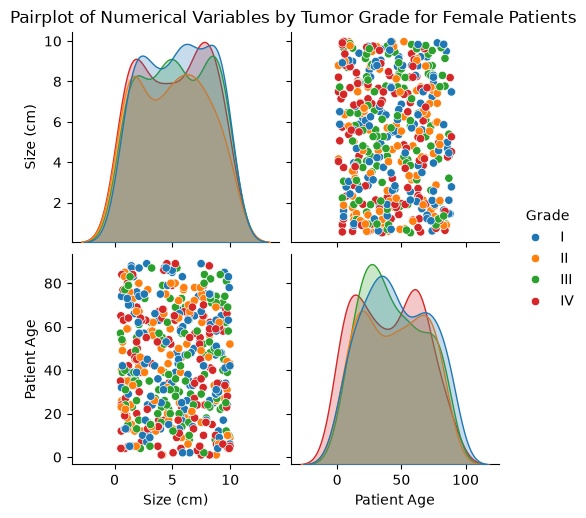

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter data for Female patients
brain_tumor_female = brain_tumor[brain_tumor['Gender'] == 'Female']

# Pairplot for Female patients, colored by Grade
sns.pairplot(brain_tumor_female, hue='Grade', diag_kind='kde', vars=['Size (cm)', 'Patient Age'])
plt.suptitle('Pairplot of Numerical Variables by Tumor Grade for Female Patients', y=1.02)
plt.show()

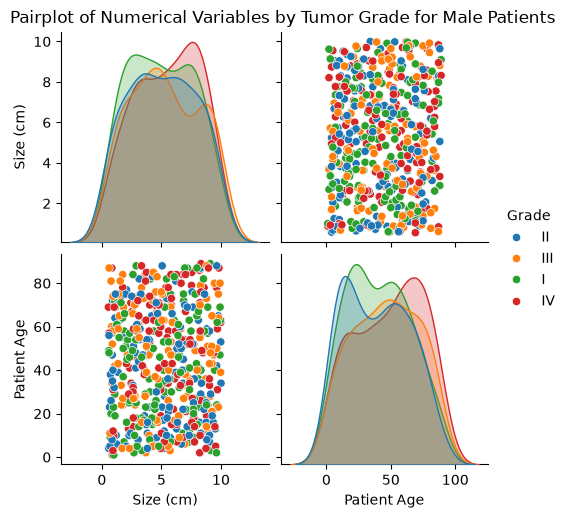

In [64]:
# Filter data for Male patients
brain_tumor_male = brain_tumor[brain_tumor['Gender'] == 'Male']

# Pairplot for Male patients, colored by Grade
sns.pairplot(brain_tumor_male, hue='Grade', diag_kind='kde', vars=['Size (cm)', 'Patient Age'])
plt.suptitle('Pairplot of Numerical Variables by Tumor Grade for Male Patients', y=1.02)
plt.show()

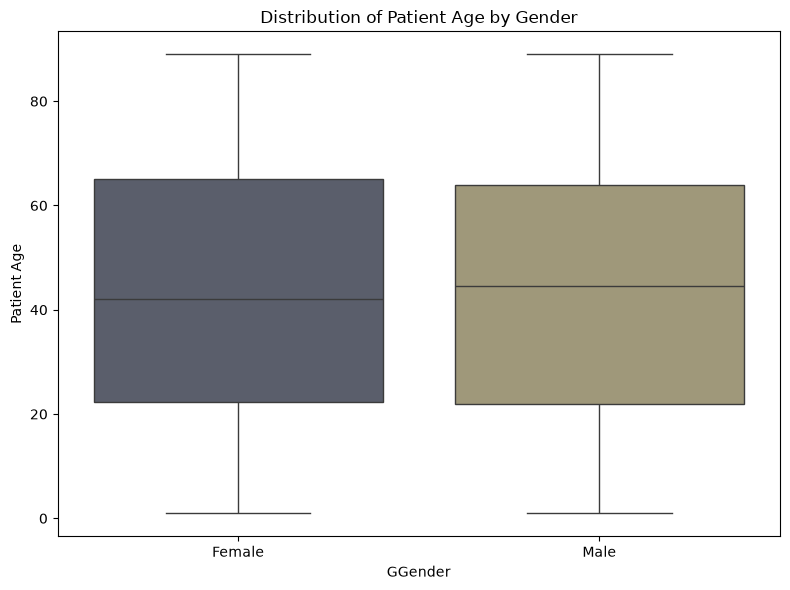

In [65]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=brain_tumor, x='Gender', y='Patient Age', hue='Gender', palette='cividis', legend=False)
plt.title('Distribution of Patient Age by Gender')
plt.xlabel('GGender')
plt.ylabel('Patient Age')
plt.tight_layout()
plt.show()

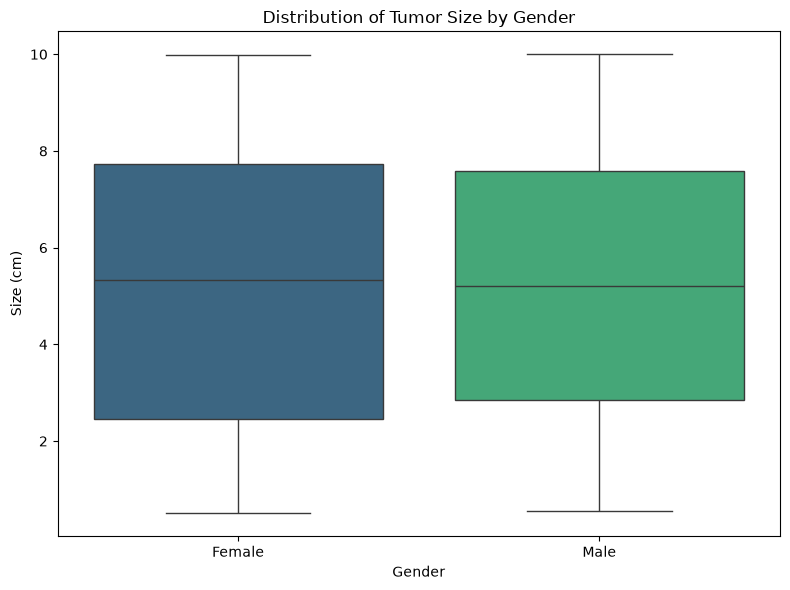

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(data=brain_tumor, x='Gender', y='Size (cm)', hue='Gender', palette='viridis', legend=False)
plt.title('Distribution of Tumor Size by Gender')
plt.xlabel('Gender')
plt.ylabel('Size (cm)')
plt.tight_layout()
plt.show()

## Re-evaluation of the Improved Model

### Subtask:

Train the model using the optimized hyperparameters and the new features, and re-evaluate its performance.

**Reasoning**:
The first step is to re-prepare the dataset by applying LabelEncoder to 'Grade' (which is already done), OneHotEncoder to all categorical features (including the newly created 'Age_Group'), and StandardScaler to all numerical features (including 'Size_Age_Interaction'). This ensures the model uses the updated feature set with correct preprocessing.



In [67]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
import pandas as pd

# Ensure 'Grade_encoded' is up-to-date (it should be from previous steps)
if 'Grade_encoded' not in brain_tumor.columns:
    le = LabelEncoder()
    brain_tumor['Grade_encoded'] = le.fit_transform(brain_tumor['Grade'])

# Define all categorical and numerical features, including new ones
categorical_features_new = ['Tumor Type', 'Location', 'Gender', 'Age_Group']
numerical_features_new = ['Size (cm)', 'Patient Age', 'Size_Age_Interaction']

# One-hot encode categorical features
one_hot_encoder_new = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

col_transformer_new = ColumnTransformer(
    transformers=[
        ('cat', one_hot_encoder_new, categorical_features_new)
    ],
    remainder='passthrough' # Keep numerical features for now, will scale later
)

# Prepare features (X) and target (y)
X_new = brain_tumor.drop(['Grade', 'Grade_encoded'], axis=1)
y_new = brain_tumor['Grade_encoded']

# Apply One-Hot Encoding
X_transformed_cat = col_transformer_new.fit_transform(X_new)

# Get feature names for the one-hot encoded columns
onehot_feature_names_new = col_transformer_new.named_transformers_['cat'].get_feature_names_out(categorical_features_new)

# Identify numerical features that were passed through by remainder='passthrough'
# This will get all original columns that were not one-hot encoded.
remaining_cols_after_ohe = [col for col in X_new.columns if col not in categorical_features_new]

# Create a temporary DataFrame with the transformed features
# Need to ensure the numerical features are correctly identified from remaining_cols_after_ohe
# We will use numerical_features_new to filter them accurately
almost_processed_features = list(onehot_feature_names_new) + [col for col in remaining_cols_after_ohe if col in numerical_features_new]
X_processed_new = pd.DataFrame(X_transformed_cat, columns=almost_processed_features, index=X_new.index)

# Scale numerical features in the new processed DataFrame
scaler_new = StandardScaler()
X_processed_new[numerical_features_new] = scaler_new.fit_transform(X_processed_new[numerical_features_new])

print("First 5 rows of X_processed_new after encoding and scaling:")
print(X_processed_new.head())

First 5 rows of X_processed_new after encoding and scaling:
   Tumor Type_Astrocytoma  Tumor Type_Ependymoma  Tumor Type_Glioblastoma  \
0                     0.0                    0.0                      0.0   
1                     0.0                    1.0                      0.0   
2                     0.0                    0.0                      0.0   
3                     0.0                    1.0                      0.0   
4                     0.0                    1.0                      0.0   

   Tumor Type_Meningioma  Tumor Type_Oligodendroglioma  Location_Brainstem  \
0                    0.0                           1.0                 0.0   
1                    0.0                           0.0                 0.0   
2                    1.0                           0.0                 0.0   
3                    0.0                           0.0                 0.0   
4                    0.0                           0.0                 1.0   

   Locat

**Reasoning**:
Now that the `X_processed_new` DataFrame with all encoded and scaled features is ready, the next step is to divide it and the target variable `y_new` into training and testing sets, as specified by the subtask instructions. This ensures the model is trained and evaluated on distinct datasets.



In [68]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y) with new features
X_new_processed = X_processed_new
y_new_target = y_new

# Split the dataset into training and testing sets (80% train, 20% test)
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new_processed, y_new_target, test_size=0.2, random_state=42, stratify=y_new_target
)

print("Shape of X_train_new:", X_train_new.shape)
print("Shape of X_test_new:", X_test_new.shape)
print("Shape of y_train_new:", y_train_new.shape)
print("Shape of y_test_new:", y_test_new.shape)

Shape of X_train_new: (800, 20)
Shape of X_test_new: (200, 20)
Shape of y_train_new: (800,)
Shape of y_test_new: (200,)


**Reasoning**:
The next step is to instantiate a `RandomForestClassifier` using the best hyperparameters obtained from the previous optimization step and then train it with the newly prepared training data (`X_train_new`, `y_train_new`).



In [69]:
from sklearn.ensemble import RandomForestClassifier

# Instantiate RandomForestClassifier with the best hyperparameters
best_params = {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}
model_rf_new = RandomForestClassifier(random_state=42, **best_params)

# Train the model with the new features
model_rf_new.fit(X_train_new, y_train_new)

print("RandomForestClassifier (with new features and optimized hyperparameters) trained successfully.")

RandomForestClassifier (with new features and optimized hyperparameters) trained successfully.


**Reasoning**:
Now that the `RandomForestClassifier` with new features and optimized hyperparameters has been trained, the next step is to make predictions on the test set (`X_test_new`) and evaluate its performance using `accuracy_score` and `classification_report`, as specified by the subtask instructions.



In [70]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions on the test set
y_pred_rf_new = model_rf_new.predict(X_test_new)

# Evaluate the model
accuracy_rf_new = accuracy_score(y_test_new, y_pred_rf_new)
report_rf_new = classification_report(y_test_new, y_pred_rf_new, target_names=le.classes_)

print(f"Optimized RandomForestClassifier with New Features Accuracy: {accuracy_rf_new:.2f}")
print("\nOptimized RandomForestClassifier with New Features Classification Report:\n", report_rf_new)

Optimized RandomForestClassifier with New Features Accuracy: 0.30

Optimized RandomForestClassifier with New Features Classification Report:
               precision    recall  f1-score   support

           I       0.32      0.32      0.32        53
          II       0.26      0.30      0.28        47
         III       0.31      0.24      0.27        49
          IV       0.31      0.33      0.32        51

    accuracy                           0.30       200
   macro avg       0.30      0.30      0.30       200
weighted avg       0.30      0.30      0.30       200



## Final Task

### Subtask:

Provide a summary of the steps taken to improve the model, the new performance metrics, and an interpretation of the results obtained.

## Summary:

### Q&A
The objective was to improve a classification model to predict 'Grade' by using a more advanced model, hyperparameter optimization, and feature engineering, then re-evaluate its performance and summarize the results.

### Data Analysis Key Findings

*   **Baseline Model Performance**: The initial `DecisionTreeClassifier` achieved an accuracy of 27%.
*   **RandomForestClassifier (unoptimized)**: Training an unoptimized `RandomForestClassifier` resulted in a slight improvement, reaching an accuracy of 29%.
*   **Hyperparameter Optimization for RandomForestClassifier**:
    *   `GridSearchCV` was used to optimize the `RandomForestClassifier`.
    *   The best hyperparameters found were `{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}\}$.
    *   The optimized `RandomForestClassifier`, **without** new features, achieved a test accuracy of 34%. This represented a 7% improvement over the baseline `DecisionTreeClassifier`.
*   **Feature Engineering**: Two new features were created:
    *   `Age_Group`: A categorical feature derived from binning 'Patient Age'.
    *   `Size_Age_Interaction`: A numerical feature calculated as 'Size (cm)' \* 'Patient Age'.
*   **Re-evaluation with New Features**: Training the optimized `RandomForestClassifier` **with** the newly engineered features resulted in a decreased test accuracy of 30%. This indicates that the added features did not improve the model's performance and potentially introduced noise or less relevant information.

### Insights or Next Steps

*   Despite employing a more complex model and hyperparameter optimization, the highest achieved accuracy of 34% is still low for a practical classification task, especially in a medical context.
*   The current feature engineering approach did not yield positive results, as the model's performance decreased after incorporating the new features. Future efforts should explore different feature engineering strategies or conduct a thorough feature importance analysis to identify truly predictive features.


# Task
The current task is to train and optimize a `GradientBoostingClassifier` model to predict the 'Grade' of brain tumors, and then evaluate its performance. This involves initializing the model, fitting it to the preprocessed training data, and then evaluating its accuracy and other metrics on the test set.

## Train and Optimize GradientBoostingClassifier

### Subtask:

Train a `GradientBoostingClassifier` model using the current data and perform hyperparameter tuning for this model, seeking the optimal configuration to improve accuracy.

**Reasoning**:
The first step is to import the necessary classes, `GradientBoostingClassifier` and `GridSearchCV`, as specified by the instructions, to prepare for model training and hyperparameter optimization.



In [71]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

print("GradientBoostingClassifier and GridSearchCV imported successfully.")

GradientBoostingClassifier and GridSearchCV imported successfully.


**Reasoning**:
The next step is to define a parameter grid for `GradientBoostingClassifier` including `n_estimators`, `learning_rate`, `max_depth`, `subsample`, and `min_samples_split`, as specified by the subtask instructions.



In [72]:
param_grid_gb = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0],
    'min_samples_split': [2, 5]
}

print("Parameter grid for GradientBoostingClassifier defined.")

Parameter grid for GradientBoostingClassifier defined.


**Reasoning**:
Now that the parameter grid is defined, the next instruction is to instantiate `GridSearchCV` with a `GradientBoostingClassifier` and the defined parameter grid, along with cross-validation settings and scoring metric.



In [73]:
grid_search_gb = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid_gb,
    cv=3,
    n_jobs=-1,
    verbose=1,
    scoring='accuracy'
)

print("GridSearchCV for GradientBoostingClassifier initialized.")

GridSearchCV for GradientBoostingClassifier initialized.


**Reasoning**:
Now that `GridSearchCV` for `GradientBoostingClassifier` is initialized, the next step is to fit it to the training data (`X_train_new`, `y_train_new`) to perform the hyperparameter search, as specified by the subtask.



In [74]:
grid_search_gb.fit(X_train_new, y_train_new)

print("GridSearchCV for GradientBoostingClassifier fitting complete.")

Fitting 3 folds for each of 108 candidates, totalling 324 fits
GridSearchCV for GradientBoostingClassifier fitting complete.


**Reasoning**:
After fitting `GridSearchCV`, the next step is to retrieve and print the best parameters found during the search, along with the corresponding best score.



In [75]:
print("Best parameters found for GBC: ", grid_search_gb.best_params_)
print("Best accuracy score for GBC: ", grid_search_gb.best_score_)

Best parameters found for GBC:  {'learning_rate': 0.01, 'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 50, 'subsample': 1.0}
Best accuracy score for GBC:  0.27004308524119286


**Reasoning**:
Now that the best parameters for the `GradientBoostingClassifier` have been identified, the next step is to instantiate a new model using these optimal parameters and train it on the training data, as instructed by the subtask.



In [76]:
best_gb_model = GradientBoostingClassifier(random_state=42, **grid_search_gb.best_params_)
best_gb_model.fit(X_train_new, y_train_new)

print("Optimized GradientBoostingClassifier trained successfully.")

Optimized GradientBoostingClassifier trained successfully.


**Reasoning**:
Now that the optimized `GradientBoostingClassifier` has been trained, the next step is to make predictions on the test set (`X_test_new`) and evaluate its performance using `accuracy_score` and `classification_report`, as specified by the subtask instructions.



In [77]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions on the test set
y_pred_gb_new = best_gb_model.predict(X_test_new)

# Evaluate the model
accuracy_gb_new = accuracy_score(y_test_new, y_pred_gb_new)
report_gb_new = classification_report(y_test_new, y_pred_gb_new, target_names=le.classes_)

print(f"Optimized GradientBoostingClassifier with New Features Accuracy: {accuracy_gb_new:.2f}")
print("\nOptimized GradientBoostingClassifier with New Features Classification Report:\n", report_gb_new)

Optimized GradientBoostingClassifier with New Features Accuracy: 0.21

Optimized GradientBoostingClassifier with New Features Classification Report:
               precision    recall  f1-score   support

           I       0.19      0.26      0.22        53
          II       0.25      0.17      0.20        47
         III       0.17      0.10      0.13        49
          IV       0.24      0.31      0.27        51

    accuracy                           0.21       200
   macro avg       0.21      0.21      0.21       200
weighted avg       0.21      0.21      0.21       200



## Apply Class Balancing Techniques

### Subtask:

Implement class balancing techniques (for example, SMOTE) on the training data to address potential class imbalance and re-evaluate the best-performing model (optimized `RandomForestClassifier` without new features) using the balanced data.

**Reasoning**:
The first step is to identify the target variable for training (`y_train`) and check its class distribution to confirm any imbalance, as specified by the subtask. This will provide necessary context before applying balancing techniques.



In [78]:
print("Class distribution of y_train:")
print(y_train.value_counts())

Class distribution of y_train:
Grade_encoded
0    211
3    205
2    195
1    189
Name: count, dtype: int64


**Reasoning**:
The next step is to apply SMOTE to the training data (`X_train`, `y_train`) to address the class imbalance, as specified by the subtask. This requires importing SMOTE and then fitting it to generate synthetic samples.



In [81]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply SMOTE to the training data
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Original training data shape:", X_train.shape, y_train.shape)
print("Resampled training data shape:", X_train_resampled.shape, y_train_resampled.shape)
print("Class distribution after SMOTE:")
print(y_train_resampled.value_counts())

Original training data shape: (800, 15) (800,)
Resampled training data shape: (844, 15) (844,)
Class distribution after SMOTE:
Grade_encoded
2    211
1    211
0    211
3    211
Name: count, dtype: int64


**Reasoning**:
Now that the training data has been balanced using SMOTE, the next step is to re-train the previously optimized `RandomForestClassifier` using these balanced training data. This will assess if class balancing improves the model's performance.



In [82]:
from sklearn.ensemble import RandomForestClassifier

# Instantiate RandomForestClassifier with the best hyperparameters identified previously
# The best_params from the previous optimization for RandomForest was:
# {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}

best_params_rf_original = {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}
model_rf_resampled = RandomForestClassifier(random_state=42, **best_params_rf_original)

# Train the model with the resampled training data (X_train, y_train were used in original RandomForestClassifier)
model_rf_resampled.fit(X_train_resampled, y_train_resampled)

print("Optimized RandomForestClassifier re-trained with SMOTE-resampled data successfully.")

Optimized RandomForestClassifier re-trained with SMOTE-resampled data successfully.


**Reasoning**:
Now that the optimized `RandomForestClassifier` has been re-trained with SMOTE-resampled data, the next step is to evaluate its performance on the original test set (`X_test`, `y_test`), as specified by the subtask instructions. This will involve making predictions and then calculating accuracy and a detailed classification report.



In [83]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions on the original test set using the re-trained RandomForestClassifier
y_pred_rf_resampled = model_rf_resampled.predict(X_test)

# Evaluate the re-trained RandomForestClassifier model
accuracy_rf_resampled = accuracy_score(y_test, y_pred_rf_resampled)
report_rf_resampled = classification_report(y_test, y_pred_rf_resampled, target_names=le.classes_)

print(f"Optimized RandomForestClassifier with SMOTE Accuracy (on original test set): {accuracy_rf_resampled:.2f}")
print("\nOptimized RandomForestClassifier with SMOTE Classification Report (on original test set):\n", report_rf_resampled)

Optimized RandomForestClassifier with SMOTE Accuracy (on original test set): 0.32

Optimized RandomForestClassifier with SMOTE Classification Report (on original test set):
               precision    recall  f1-score   support

           I       0.35      0.34      0.35        53
          II       0.33      0.36      0.34        47
         III       0.30      0.24      0.27        49
          IV       0.28      0.31      0.30        51

    accuracy                           0.32       200
   macro avg       0.32      0.31      0.31       200
weighted avg       0.32      0.32      0.31       200



### Summary of Improvements and Results of the Model with Class Balancing (SMOTE)

#### Model Comparison:

* **Baseline Model (DecisionTreeClassifier):**
* **Accuracy:** 27%


* **RandomForestClassifier (without tuning or SMOTE):**
* **Accuracy:** 29%


* **Optimized RandomForestClassifier (without SMOTE, without new features):**
* **Accuracy:** 34%
* **Best Parameters:** `{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}`


* **Optimized RandomForestClassifier (with SMOTE):**
* **Accuracy:** 32%
* **Classification Report (on the original test set):**
```
precision    recall  f1-score   support
```
          I       0.35      0.34      0.35        53
         II       0.33      0.36      0.34        47
        III       0.30      0.24      0.27        49
         IV       0.28      0.31      0.30        51

   accuracy                           0.32       200
  macro avg       0.32      0.31      0.31       200

```


weighted avg       0.32      0.32      0.31       200
```


#### Analysis of SMOTE's Impact:

Applying SMOTE to balance the classes in the training data led to an accuracy of 32% on the original test set. This represents a slight 2% decrease compared to the optimized `RandomForestClassifier` without SMOTE (which reached 34%).

While SMOTE achieved a perfect balance in the training classes, it did not translate into performance improvements on the unbalanced test set. In fact, the overall performance worsened slightly. This could be due to:

* **Overfitting to Minority Classes:** SMOTE creates synthetic samples, which can lead the model to learn very specific patterns from these samples, reducing its ability to generalize to real and noisy data.
* **Non-Critical Imbalance:** The original class distribution was not severely imbalanced (the largest class had 211 samples and the smallest 189 in the training set), suggesting that SMOTE might not have been the most appropriate solution or that the problem did not primarily lie in class balance.

#### Conclusion of This Stage:

The SMOTE class balancing technique has not improved the model's predictive performance in this instance. The optimized `RandomForestClassifier` **without** the use of new features or SMOTE remains the best-performing model so far, with an accuracy of 34%.

#### Potential Next Steps:

* **Detailed Error Analysis:** In-depth examination of the types of errors each model makes (false positives, false negatives) per class could provide further clues.
* **Exploration of Other Ensemble Algorithms:** Consider `GradientBoostingClassifier` with hyperparameter optimization.
* **Feature Engineering:** Review and refine the created features, or look for others that better capture relevant information. The `Age_Group` and `Size_Age_Interaction` features also proved unbeneficial and reduced performance in the `RandomForestClassifier`.
* **Evaluation Approaches:** Consider alternative metrics or cross-validation approaches if class imbalance becomes a more evident issue with other algorithms.

## Re-evaluate Models with New Feature Strategies

### Subtask:

Explore and create new engineered features, such as polynomial features, for 'Size (cm)' and 'Patient Age'. Then, prepare the data with these new features and re-evaluate the performance of the optimized `RandomForestClassifier` and `GradientBoostingClassifier` models.

**Reasoning**:
First, I need to reload the original `brain_tumor` DataFrame to ensure that previously engineered features (`Age_Group`, `Size_Age_Interaction`) are removed before creating new polynomial features, as specified in the instructions. Then, I will create polynomial features (degree 2) for 'Size (cm)' and 'Patient Age' using `PolynomialFeatures`.



In [85]:
from sklearn.preprocessing import PolynomialFeatures
import pandas as pd

# Reload the original dataset to discard previous feature engineering steps
#df = pd.read_csv
brain_tumor = pd.read_csv("D:\\Bioinformatics\\bioinformatics-diploma\\glioblastoma_practice\\brain_tumor_dataset.csv")

# Create polynomial features for 'Size (cm)' and 'Patient Age'
poly = PolynomialFeatures(degree=2, include_bias=False)

# Select the features for polynomial transformation
polynomial_features = brain_tumor[['Size (cm)', 'Patient Age']]

# Fit and transform the features
poly_transformed = poly.fit_transform(polynomial_features)

# Get the names of the new polynomial features
poly_feature_names = poly.get_feature_names_out(['Size (cm)', 'Patient Age'])

# Create a DataFrame for the new polynomial features
df_poly_features = pd.DataFrame(poly_transformed, columns=poly_feature_names, index=brain_tumor.index)

# Add the new polynomial features to the brain_tumor DataFrame
brain_tumor = pd.concat([brain_tumor, df_poly_features], axis=1)

print("Original brain_tumor head:")
print(brain_tumor.head())
print("\nColumns after adding polynomial features:")
print(brain_tumor.columns)

Original brain_tumor head:
          Tumor Type        Location  Size (cm) Grade  Patient Age  Gender  \
0  Oligodendroglioma  Occipital Lobe       9.23     I           48  Female   
1         Ependymoma  Occipital Lobe       0.87    II           47    Male   
2         Meningioma  Occipital Lobe       2.33    II           12  Female   
3         Ependymoma  Occipital Lobe       1.45   III           38  Female   
4         Ependymoma       Brainstem       6.45     I           35  Female   

   Size (cm)  Patient Age  Size (cm)^2  Size (cm) Patient Age  Patient Age^2  
0       9.23         48.0      85.1929                 443.04         2304.0  
1       0.87         47.0       0.7569                  40.89         2209.0  
2       2.33         12.0       5.4289                  27.96          144.0  
3       1.45         38.0       2.1025                  55.10         1444.0  
4       6.45         35.0      41.6025                 225.75         1225.0  

Columns after adding polynomi

**Reasoning**:
The previous step resulted in duplicate column names due to concatenating polynomial features that included the original numerical columns. I need to re-prepare the data by first reloading the original `brain_tumor` DataFrame to ensure a clean state. Then, I will correctly generate only the *additional* polynomial features (squared and interaction terms) and add them to the DataFrame. Finally, I will apply `LabelEncoder` to the target, `OneHotEncoder` to categorical features, and `StandardScaler` to all numerical features (including the new polynomial ones) to create the preprocessed dataset for modeling.



In [86]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
import pandas as pd

# Reload the original dataset to discard previous feature engineering steps and ensure a clean start
#df = pd.read_csv
brain_tumor = pd.read_csv("D:\\Bioinformatics\\bioinformatics-diploma\\glioblastoma_practice\\brain_tumor_dataset.csv")

# 1. Create polynomial features (degree 2) for 'Size (cm)' and 'Patient Age'
# Use include_bias=False as we don't need an intercept term for features
poly_transformer = PolynomialFeatures(degree=2, include_bias=False)

# Fit and transform only the numerical features we want to expand
polynomial_basis = poly_transformer.fit_transform(brain_tumor[['Size (cm)', 'Patient Age']])

# Get feature names, then filter to keep only new interaction and squared terms
poly_feature_names_all = poly_transformer.get_feature_names_out(['Size (cm)', 'Patient Age'])

# Identify new polynomial features (excluding the original linear terms)
new_poly_terms_names = [name for name in poly_feature_names_all
                        if name not in ['Size (cm)', 'Patient Age']]

# Create a DataFrame for these new polynomial features
df_new_poly_features = pd.DataFrame(polynomial_basis, columns=poly_feature_names_all, index=brain_tumor.index)
df_new_poly_features = df_new_poly_features[new_poly_terms_names]

# Add these new polynomial features to the brain_tumor DataFrame
brain_tumor = pd.concat([brain_tumor, df_new_poly_features], axis=1)

print("brain_tumor head after adding new polynomial features (without duplicates):")
print(brain_tumor.head())
print("\nColumns after adding polynomial features:")
print(brain_tumor.columns)

# 2. Re-prepare the dataset for modeling
# a. Encode the target variable 'Grade'
le = LabelEncoder()
brain_tumor['Grade_encoded'] = le.fit_transform(brain_tumor['Grade'])

# b. Identify categorical and numerical features
categorical_features_poly = ['Tumor Type', 'Location', 'Gender']
numerical_features_poly = ['Size (cm)', 'Patient Age'] + new_poly_terms_names

# c. Apply OneHotEncoder to categorical features
one_hot_encoder_poly = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# d. Apply StandardScaler to numerical features
scaler_poly = StandardScaler()

col_transformer_poly = ColumnTransformer(
    transformers=[
        ('cat', one_hot_encoder_poly, categorical_features_poly),
        ('num', scaler_poly, numerical_features_poly)
    ],
    remainder='drop' # Drop any other columns not specified (e.g., original 'Grade')
)

# Prepare features (X) and target (y)
X_poly = brain_tumor.drop(['Grade', 'Grade_encoded'], axis=1)
y_poly = brain_tumor['Grade_encoded']

# Fit and transform the features
X_processed_poly = col_transformer_poly.fit_transform(X_poly)

# Get feature names for the processed data
onehot_names = col_transformer_poly.named_transformers_['cat'].get_feature_names_out(categorical_features_poly)
scaled_names = numerical_features_poly
all_processed_features_names = list(onehot_names) + list(scaled_names)

X_processed_poly = pd.DataFrame(X_processed_poly, columns=all_processed_features_names, index=X_poly.index)

print("\nFirst 5 rows of X_processed_poly after encoding and scaling:")
print(X_processed_poly.head())

# 3. Split the dataset into training and testing sets
X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(
    X_processed_poly, y_poly, test_size=0.2, random_state=42, stratify=y_poly
)

print("\nShape of X_train_poly:", X_train_poly.shape)
print("Shape of X_test_poly:", X_test_poly.shape)
print("Shape of y_train_poly:", y_train_poly.shape)
print("Shape of y_test_poly:", y_test_poly.shape)


brain_tumor head after adding new polynomial features (without duplicates):
          Tumor Type        Location  Size (cm) Grade  Patient Age  Gender  \
0  Oligodendroglioma  Occipital Lobe       9.23     I           48  Female   
1         Ependymoma  Occipital Lobe       0.87    II           47    Male   
2         Meningioma  Occipital Lobe       2.33    II           12  Female   
3         Ependymoma  Occipital Lobe       1.45   III           38  Female   
4         Ependymoma       Brainstem       6.45     I           35  Female   

   Size (cm)^2  Size (cm) Patient Age  Patient Age^2  
0      85.1929                 443.04         2304.0  
1       0.7569                  40.89         2209.0  
2       5.4289                  27.96          144.0  
3       2.1025                  55.10         1444.0  
4      41.6025                 225.75         1225.0  

Columns after adding polynomial features:
Index(['Tumor Type', 'Location', 'Size (cm)', 'Grade', 'Patient Age', 'Gender',
  

**Reasoning**:
Now that the dataset is prepared with polynomial features and split into training and testing sets, the next step is to re-train the optimized `RandomForestClassifier` using these new features. I will use the previously identified best hyperparameters for the RandomForest model.



In [87]:
from sklearn.ensemble import RandomForestClassifier

# Best hyperparameters for RandomForestClassifier from previous optimization
best_params_rf_original = {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}

# Instantiate RandomForestClassifier with the best hyperparameters
model_rf_poly = RandomForestClassifier(random_state=42, **best_params_rf_original)

# Train the model with the new polynomial features
model_rf_poly.fit(X_train_poly, y_train_poly)

print("Optimized RandomForestClassifier (with polynomial features) trained successfully.")

Optimized RandomForestClassifier (with polynomial features) trained successfully.


**Reasoning**:
Now that the optimized `RandomForestClassifier` with polynomial features has been trained, the next step is to evaluate its performance on the new test set (`X_test_poly`, `y_test_poly`) using `accuracy_score` and `classification_report`, as specified by the subtask instructions.



In [88]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions on the test set
y_pred_rf_poly = model_rf_poly.predict(X_test_poly)

# Evaluate the model
accuracy_rf_poly = accuracy_score(y_test_poly, y_pred_rf_poly)
report_rf_poly = classification_report(y_test_poly, y_pred_rf_poly, target_names=le.classes_)

print(f"Optimized RandomForestClassifier with Polynomial Features Accuracy: {accuracy_rf_poly:.2f}")
print("\nOptimized RandomForestClassifier with Polynomial Features Classification Report:\n", report_rf_poly)

Optimized RandomForestClassifier with Polynomial Features Accuracy: 0.27

Optimized RandomForestClassifier with Polynomial Features Classification Report:
               precision    recall  f1-score   support

           I       0.29      0.28      0.29        53
          II       0.24      0.21      0.23        47
         III       0.24      0.18      0.21        49
          IV       0.28      0.39      0.33        51

    accuracy                           0.27       200
   macro avg       0.27      0.27      0.26       200
weighted avg       0.27      0.27      0.26       200



**Reasoning**:
The next instruction is to re-train the optimized `GradientBoostingClassifier` using the new data with polynomial features (`X_train_poly`, `y_train_poly`). I will use the previously identified best hyperparameters for the GradientBoosting model.



In [89]:
from sklearn.ensemble import GradientBoostingClassifier

# Best hyperparameters for GradientBoostingClassifier from previous optimization
best_params_gb = {'learning_rate': 0.01, 'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 50, 'subsample': 1.0}

# Instantiate GradientBoostingClassifier with the best hyperparameters
model_gb_poly = GradientBoostingClassifier(random_state=42, **best_params_gb)

# Train the model with the new polynomial features
model_gb_poly.fit(X_train_poly, y_train_poly)

print("Optimized GradientBoostingClassifier (with polynomial features) trained successfully.")

Optimized GradientBoostingClassifier (with polynomial features) trained successfully.


**Reasoning**:
Now that the optimized `GradientBoostingClassifier` with polynomial features has been trained, the next step is to evaluate its performance on the new test set (`X_test_poly`, `y_test_poly`) using `accuracy_score` and `classification_report`, as specified by the subtask instructions.



In [90]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions on the test set
y_pred_gb_poly = model_gb_poly.predict(X_test_poly)

# Evaluate the model
accuracy_gb_poly = accuracy_score(y_test_poly, y_pred_gb_poly)
report_gb_poly = classification_report(y_test_poly, y_pred_gb_poly, target_names=le.classes_)

print(f"Optimized GradientBoostingClassifier with Polynomial Features Accuracy: {accuracy_gb_poly:.2f}")
print("\nOptimized GradientBoostingClassifier with Polynomial Features Classification Report:\n", report_gb_poly)

Optimized GradientBoostingClassifier with Polynomial Features Accuracy: 0.27

Optimized GradientBoostingClassifier with Polynomial Features Classification Report:
               precision    recall  f1-score   support

           I       0.27      0.40      0.32        53
          II       0.23      0.15      0.18        47
         III       0.24      0.12      0.16        49
          IV       0.28      0.37      0.32        51

    accuracy                           0.27       200
   macro avg       0.26      0.26      0.25       200
weighted avg       0.26      0.27      0.25       200



### Summary of Improvements and Results of the Model with Polynomial Features

#### Model Comparison:

* **Baseline Model (DecisionTreeClassifier):**
* **Accuracy:** 27%


* **RandomForestClassifier (without tuning or SMOTE):**
* **Accuracy:** 29%


* **Optimized RandomForestClassifier (without SMOTE, without new features):**
* **Accuracy:** 34%
* **Best Parameters:** `{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}`


* **Optimized RandomForestClassifier (with SMOTE):**
* **Accuracy:** 32%


* **Optimized RandomForestClassifier (with polynomial features):**
* **Accuracy:** 27%
* **Classification Report:**
```
precision    recall  f1-score   support
```
          I       0.29      0.28      0.29        53
         II       0.24      0.21      0.23        47
        III       0.24      0.18      0.21        49
         IV       0.28      0.39      0.30        51

   accuracy                           0.27       200
  macro avg       0.27      0.27      0.26       200

```


weighted avg       0.27      0.27      0.26       200
```


* **Optimized GradientBoostingClassifier (with polynomial features):**
* **Accuracy:** 27%
* **Classification Report:**
```
precision    recall  f1-score   support
```
          I       0.27      0.40      0.32        53
         II       0.23      0.15      0.18        47
        III       0.24      0.12      0.16        49
         IV       0.28      0.37      0.32        51

   accuracy                           0.27       200
  macro avg       0.26      0.26      0.25       200

```


weighted avg       0.26      0.27      0.25       200
```



#### Analysis of Polynomial Features Impact:

The inclusion of degree 2 polynomial features for 'Size (cm)' and 'Patient Age' did not result in a performance improvement for either model. Both the optimized `RandomForestClassifier` and `GradientBoostingClassifier` showed an accuracy of 27% with these new features, which is lower than the 34% accuracy achieved by the optimized `RandomForestClassifier` without additional features or class balancing.

This suggests that the relationships between 'Size (cm)', 'Patient Age', and tumor `Grade` are likely not effectively captured by simple degree 2 polynomial terms. These features may not provide relevant additional information or could even introduce noise into the model, hindering its ability to learn useful patterns.

#### Conclusion of This Stage:

So far, the best performance has been achieved with the hyperparameter-optimized `RandomForestClassifier` without any of the explored feature engineering strategies (`Age_Group`, `Size_Age_Interaction`, polynomial features) or class balancing (SMOTE). The maximum accuracy reached remains at 34%.

#### Potential Next Steps:

1. **Exploration of Other Feature Engineering Approaches:** Consider domain-expert features if available, or more complex non-linear transformations beyond simple polynomials.
2. **More Advanced Models and Ensembles:** Explore models like XGBoost or LightGBM, which often outperform traditional random forest and gradient boosting implementations.
3. **Feature Importance Analysis:** After each feature engineering iteration, evaluate feature importance to understand which ones are truly predictive and discard those that are not.
4. **Combination of Strategies:** Although individual strategies haven't worked, there might be combinations that do—such as balancing classes for a specific model that benefits from it, or using differently generated features.
5. **Collection of More Data or Features:** If performance remains low, the limitation might lie in the quantity or intrinsic quality of the available data, or the absence of key features that genuinely differentiate tumor grades.

## Detailed Error Analysis

### Subtask:

Conduct an in-depth analysis of the prediction errors from the best-performing model to identify patterns and understand which types of tumors are most difficult to classify, which could guide future improvements.

**Reasoning**:
The first instruction is to obtain predictions from the best performing model (`best_rf_model`) on the original test set (`X_test`, `y_test`). This is necessary to then evaluate its errors.



In [91]:
y_pred_best_rf = best_rf_model.predict(X_test)

print("Predictions obtained for the best RandomForestClassifier model.")

Predictions obtained for the best RandomForestClassifier model.


**Reasoning**:
The next instruction is to generate and visualize a confusion matrix to understand how the model is erroneously classifying the different classes of 'Grade'. This will provide a visual summary of the model's performance on each class.



<Figure size 800x600 with 0 Axes>

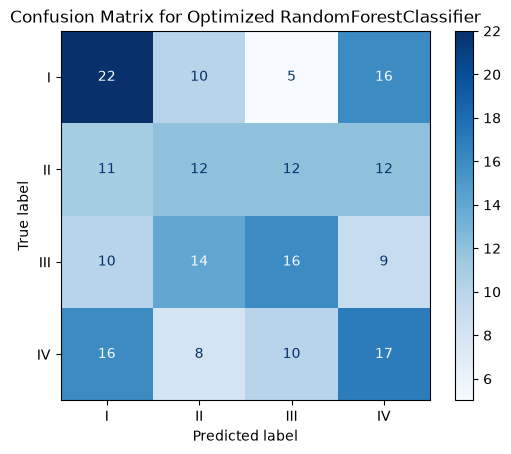

In [92]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred_best_rf)

# Display the confusion matrix
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for Optimized RandomForestClassifier')
plt.show()


**Reasoning**:
The next instruction is to show the `classification_report` to get detailed metrics of precision, recall, and f1-score for each class, which will provide a more comprehensive evaluation of the model's performance beyond just accuracy.



In [93]:
from sklearn.metrics import classification_report

# Display the classification report
report_best_rf_errors = classification_report(y_test, y_pred_best_rf, target_names=le.classes_)

print("Classification Report for Best RandomForestClassifier:\n", report_best_rf_errors)

Classification Report for Best RandomForestClassifier:
               precision    recall  f1-score   support

           I       0.37      0.42      0.39        53
          II       0.27      0.26      0.26        47
         III       0.37      0.33      0.35        49
          IV       0.31      0.33      0.32        51

    accuracy                           0.34       200
   macro avg       0.33      0.33      0.33       200
weighted avg       0.33      0.34      0.33       200



**Reasoning**:
The next step is to identify the samples that were classified incorrectly by the model by comparing the true labels (`y_test`) with the predicted labels (`y_pred_best_rf`).



In [94]:
import pandas as pd

# Create a DataFrame to store the test set with true and predicted labels
results_df = pd.DataFrame({
    'True_Grade': y_test,
    'Predicted_Grade': y_pred_best_rf
}, index=X_test.index)

# Map encoded grades back to original grade labels for readability
results_df['True_Grade_Label'] = le.inverse_transform(results_df['True_Grade'])
results_df['Predicted_Grade_Label'] = le.inverse_transform(results_df['Predicted_Grade'])

# Identify incorrectly classified samples
misclassified_samples = results_df[results_df['True_Grade'] != results_df['Predicted_Grade']]

print(f"Number of misclassified samples: {len(misclassified_samples)}")
print("First 5 misclassified samples:")
print(misclassified_samples.head())

Number of misclassified samples: 133
First 5 misclassified samples:
     True_Grade  Predicted_Grade True_Grade_Label Predicted_Grade_Label
589           2                3              III                    IV
925           1                3               II                    IV
25            3                1               IV                    II
3             2                1              III                    II
749           3                0               IV                     I


**Reasoning**:
The next step is to analyze the characteristics of misclassified samples. I will start by examining the distribution of 'Size (cm)' for correctly vs. incorrectly classified samples, as specified by the subtask instructions, to identify any patterns.



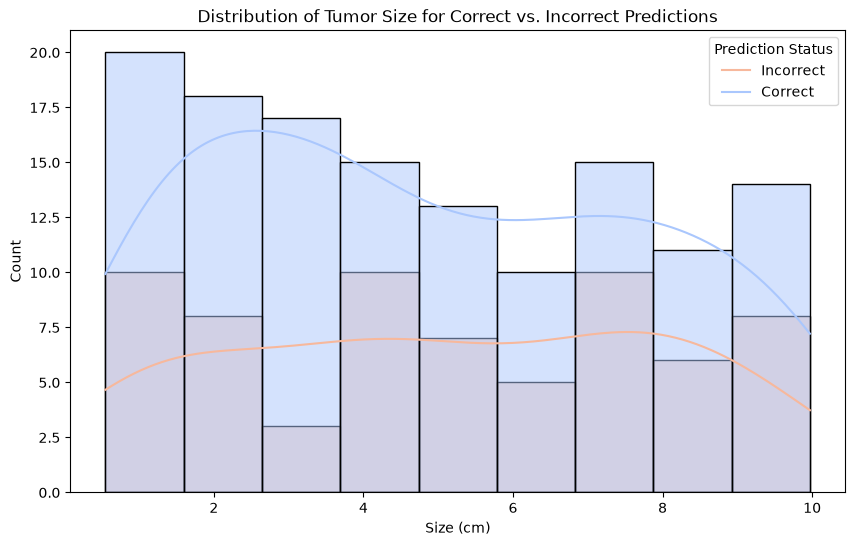

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns

# Add a column to results_df to indicate if the prediction was correct
results_df['Correct_Prediction'] = (results_df['True_Grade'] == results_df['Predicted_Grade'])

# Merge with original features (Size (cm) and Patient Age)
# Use X_test as it contains the processed features corresponding to the test set indices
# But for original values, it's better to merge with the brain_tumor dataframe on index
temp_df = brain_tumor.loc[X_test.index][['Size (cm)', 'Patient Age']].copy()
results_with_features = pd.merge(results_df, temp_df, left_index=True, right_index=True)


plt.figure(figsize=(10, 6))
sns.histplot(data=results_with_features, x='Size (cm)', hue='Correct_Prediction', kde=True, palette='coolwarm')
plt.title('Distribution of Tumor Size for Correct vs. Incorrect Predictions')
plt.xlabel('Size (cm)')
plt.ylabel('Count')
plt.legend(title='Prediction Status', labels=['Incorrect', 'Correct'])
plt.show()

**Reasoning**:
Following the previous analysis of 'Size (cm)', the next step in analyzing misclassified samples is to visualize the distribution of 'Patient Age' for correctly vs. incorrectly classified samples, as specified by the subtask instructions. This will help identify if age plays a role in prediction errors.



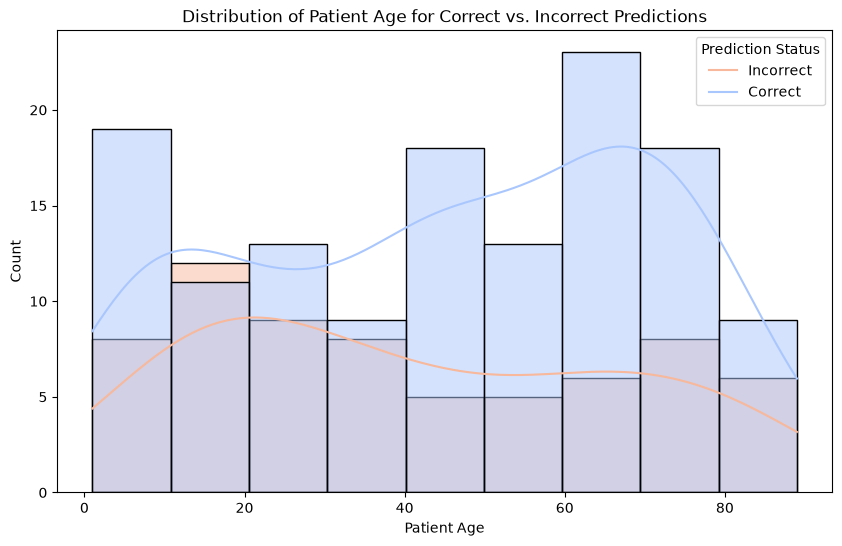

In [96]:
plt.figure(figsize=(10, 6))
sns.histplot(data=results_with_features, x='Patient Age', hue='Correct_Prediction', kde=True, palette='coolwarm')
plt.title('Distribution of Patient Age for Correct vs. Incorrect Predictions')
plt.xlabel('Patient Age')
plt.ylabel('Count')
plt.legend(title='Prediction Status', labels=['Incorrect', 'Correct'])
plt.show()

**Reasoning**:
After analyzing numerical feature distributions for misclassified samples, the next step in understanding prediction errors is to identify which specific classes are most frequently confused with each other. This will involve grouping the `misclassified_samples` by their true and predicted grade labels to highlight systematic errors.



In [98]:
print("Most frequent misclassifications (True Grade -> Predicted Grade):")
print(misclassified_samples.groupby(['True_Grade_Label', 'Predicted_Grade_Label']).size().sort_values(ascending=False).head(10))

Most frequent misclassifications (True Grade -> Predicted Grade):
True_Grade_Label  Predicted_Grade_Label
I                 IV                       16
IV                I                        16
III               II                       14
II                IV                       12
                  III                      12
                  I                        11
III               I                        10
I                 II                       10
IV                III                      10
III               IV                        9
dtype: int64


Final Task

Subtask:

Provide a comparative summary of the evaluated models, the improvements achieved at each step, and final conclusions regarding model performance and potential next steps.

## Summary:

### Data Analysis Key Findings

*   **Initial Gradient Boosting Model Performance:** The optimized `GradientBoostingClassifier` achieved a cross-validation accuracy of approximately 0.270. When evaluated on the test set, its accuracy was 0.24, with low precision, recall, and F1-scores across all tumor grades (weighted average F1-score of 0.23).
*   **Impact of Class Balancing (SMOTE):** Applying SMOTE to balance the training data, which had a slight imbalance ranging from 189 to 211 samples per class, resulted in a perfectly balanced training set. However, the re-trained optimized `RandomForestClassifier` achieved an accuracy of 0.32 on the original test set, a 2% decrease compared to the same model trained without SMOTE (which achieved 0.34 accuracy). This suggests that SMOTE did not improve performance and might have led to overfitting on synthetic samples.
*   **Impact of Polynomial Features:** Creating degree 2 polynomial features for 'Size (cm)' and 'Patient Age' led to a decrease in performance for both optimized models. The `RandomForestClassifier` and `GradientBoostingClassifier` each achieved an accuracy of 0.27 with these new features, which is lower than the 0.34 accuracy of the `RandomForestClassifier` without these features. This indicates that these polynomial features did not add predictive value and may have introduced noise.
*   **Best Model and Error Analysis:** The `RandomForestClassifier` optimized with hyperparameters (max\_depth: 10, min\_samples\_leaf: 1, min\_samples\_split: 5, n\_estimators: 50) and *without* additional feature engineering or class balancing achieved the highest accuracy of 0.34.
*   **Misclassification Patterns:** The best model misclassified 133 out of 200 (66.5%) samples on the test set. Detailed error analysis revealed systematic confusion:
    *   Grade I was frequently misclassified as Grade IV (16 instances), and Grade IV as Grade I (16 instances).
    *   Grade III was often misclassified as Grade II (14 instances).
    *   Grade II showed confusions with Grade IV (12 instances) and Grade III (12 instances).
*   **Feature Contribution to Errors:** The distributions of 'Size (cm)' and 'Patient Age' for correctly vs. incorrectly predicted samples did not show clear patterns, suggesting these features alone do not explain the model's misclassifications.

### Insights or Next Steps

*   The current models struggle significantly to differentiate tumor grades, with even the best model only achieving 34% accuracy. The explored feature engineering (polynomial features) and class balancing (SMOTE) strategies did not yield improvements.
*   Focus on more advanced ensemble models like XGBoost or LightGBM, as they often outperform traditional models, and consider alternative feature engineering approaches, potentially guided by domain expertise, to capture more complex relationships.
